# DM2 - Questions 1, 2 et 3

Ce notebook teste la classification binaire chiffre à chiffre en utilisant une méthode adaboost. Pour chaque paire de chiffre on entraine **Adaboost** avec trois classifieurs faibles : 
- stump
- perceptron
- arbre de décision de profondeurs 3, 5, 10

Dans un premier temps, on a fait les entrainements dans les **784 pixels de l'image** puis en utilisant un **embedding** : les 64 neuronnes << 784 de la couche caché d'un MLP.


Les modèles sont comparés sur leur **F1 score** (F1 macro : moyenne du F1 de chacun des deux chiffres de la paire).



Pour le MLP utilisé lors de l'embedding, on a utilisé le **MLPRegressor** de scikit-learn. On a utilisé un chatbot pour implémenter ce MLP.

On étudiera dans ce notebook les combinaisons de chiffres 3-8 comme exemple d'illustration puis on montreras les résultats de l'analyse globale réalisé dans le notebook "etude_complete_toute_paires.ipynb"

# 1. Chargement des données

In [12]:
# chargement des bibliothèques

import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.datasets import fetch_openml
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Perceptron
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

random_seed = 1234

In [ ]:
# Chargement des données MNIST 784.

mnist = fetch_openml('mnist_784', version=1, data_home="data", as_frame=False, parser='liac-arff')

# Mise à l'échelle des données
Xtrain = (mnist.data[0:60000] / 255.0).astype(np.float32)
Ytrain = mnist.target[0:60000].astype(int)

Xtest = (mnist.data[60000:70000] / 255.0).astype(np.float32)
Ytest = mnist.target[60000:70000].astype(int)

print(Xtrain.shape, Xtest.shape)

(60000, 784) (10000, 784)


Embedding : (60000, 64) (10000, 64)


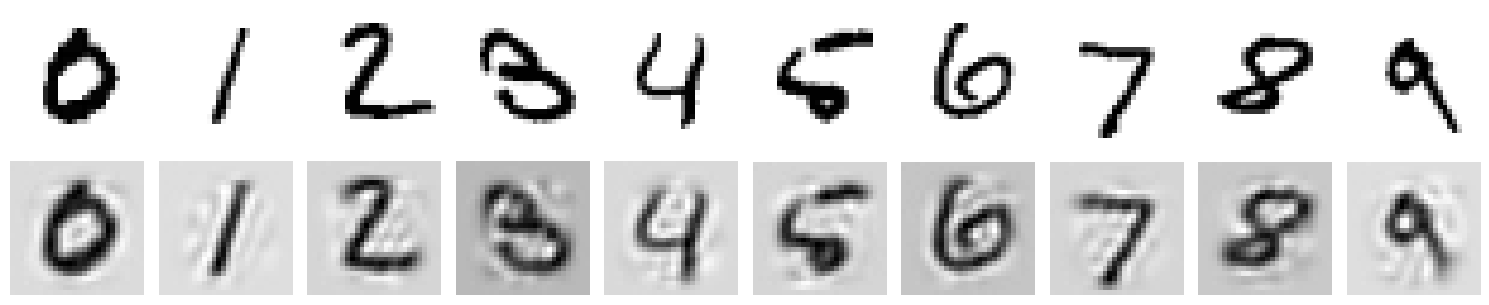

In [8]:
# Définition de l'embedding 784 -> 64 -> 784
autoencodeur = MLPRegressor(hidden_layer_sizes=(64,), activation="relu",
                            max_iter=30, random_state=random_seed)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)   # 30 époques ne suffisent pas à converger : on masque l'avertissement
    autoencodeur.fit(Xtrain, Xtrain)

# Poids de la couche cachée
W_enc = autoencodeur.coefs_[0]        # forme (784, 64)
b_enc = autoencodeur.intercepts_[0]   # forme (64,)

def encoder(X):
    """Passe des pixels (784) à l'embedding (64) : activité des neurones cachés (ReLU)."""
    return np.maximum(X @ W_enc + b_enc, 0)

Ztrain = encoder(Xtrain)
Ztest = encoder(Xtest)
print("Embedding :", Ztrain.shape, Ztest.shape)

# Contrôle visuel : images d'origine (en haut) et reconstruites par le MLP (en bas)
reconstruction = autoencodeur.predict(Xtest)

fig, axs = plt.subplots(2, 10, figsize=(15, 3.4))
for j in range(10):
    i = np.flatnonzero(Ytest == j)[0]          # premier exemple du chiffre j dans le test
    axs[0, j].imshow(Xtest[i].reshape(28, 28), cmap="gray_r")
    axs[1, j].imshow(reconstruction[i].reshape(28, 28), cmap="gray_r")
    axs[0, j].axis("off")
    axs[1, j].axis("off")
plt.tight_layout()
plt.show()


In [9]:
def afficher_resultats(modele, X_test, y_test, etiquettes, titre):
    """Affiche la matrice de confusion et la carte de saillance d'un AdaBoost entraîné sur les pixels.
    Renvoie le F1 macro sur le test."""
    pred = modele.predict(X_test)
    f1 = f1_score(y_test, pred, average="macro")

    # Saillance : importance de chaque pixel
    if isinstance(modele.estimators_[0], Perceptron):
        # perceptron : somme des poids de chaque perceptron, pondérée par son poids dans le boosting (carte signée)
        carte = sum(a * clf.coef_[0] / np.linalg.norm(clf.coef_[0])
                    for clf, a in zip(modele.estimators_, modele.estimator_weights_))
    else:
        # stumps et arbres : importance des pixels calculée par scikit-learn
        carte = modele.feature_importances_
    carte = carte.reshape(28, 28)

    fig, axs = plt.subplots(1, 2, figsize=(9, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=etiquettes).plot(
        ax=axs[0], cmap="Blues", colorbar=False)
    axs[0].set_title("Matrice de confusion (test)")
    if isinstance(modele.estimators_[0], Perceptron):
        vmax = np.abs(carte).max()
        axs[1].imshow(carte, cmap="bwr", vmin=-vmax, vmax=vmax)
        axs[1].set_title(f"Saillance (rouge → {etiquettes[1]}, bleu → {etiquettes[0]})")
    else:
        axs[1].imshow(carte, cmap="hot")
        axs[1].set_title("Saillance")
    axs[1].axis("off")
    fig.suptitle(f"{titre} - F1 = {f1:.4f}")
    plt.tight_layout()
    plt.show()
    return f1


In [18]:
def afficher_resultats_embedding(modele, Z_train, y_train, Z_test, y_test, X_test, etiquettes, titre):
    """Comme afficher_resultats, pour un AdaBoost entraîné sur l'embedding.
    La carte de saillance est ramenée des 64 neurones cachés vers les 784 pixels."""
    pred = modele.predict(Z_test)
    f1 = f1_score(y_test, pred, average="macro")

    # 1. Importance signée de chaque neurone caché
    if isinstance(modele.estimators_[0], Perceptron):
        coef = sum(a * clf.coef_[0] / np.linalg.norm(clf.coef_[0])
                   for clf, a in zip(modele.estimators_, modele.estimator_weights_))
    else:
        signe = np.sign(Z_train[y_train == 1].mean(axis=0) - Z_train[y_train == 0].mean(axis=0))
        coef = modele.feature_importances_ * signe

    # 2. Rétropropagation vers les pixels : poids du MLP x proportion d'images où le neurone est actif (ReLU)
    derivee_moyenne = ((X_test @ W_enc + b_enc) > 0).mean(axis=0)
    carte = (W_enc @ (coef * derivee_moyenne)).reshape(28, 28)

    # 3. Affichage
    fig, axs = plt.subplots(1, 2, figsize=(9, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=etiquettes).plot(
        ax=axs[0], cmap="Blues", colorbar=False)
    axs[0].set_title("Matrice de confusion (test)")
    vmax = np.abs(carte).max()
    axs[1].imshow(carte, cmap="bwr", vmin=-vmax, vmax=vmax)
    axs[1].set_title(f"Saillance (rouge → {etiquettes[1]}, bleu → {etiquettes[0]})")
    axs[1].axis("off")
    fig.suptitle(f"{titre} - F1 = {f1:.4f}")
    plt.tight_layout()
    plt.show()
    return f1


# 2. Classification des 3 vs 8





## Image brute



In [23]:
# Sélection des 3 et des 8 dans les données d'entraînement et de test, pour une tâche binaire
idx_train = (Ytrain == 3) | (Ytrain == 8)
idx_test = (Ytest == 3) | (Ytest == 8)

X38_train, y38_train = Xtrain[idx_train], (Ytrain[idx_train] == 8).astype(int)
X38_test, y38_test = Xtest[idx_test], (Ytest[idx_test] == 8).astype(int)

f1_38 = {}   # F1 de chaque modèle, pour le bilan
modeles_38 = {}   # modèles entraînés, pour les courbes du bilan

print(X38_train.shape, X38_test.shape)


(11982, 784) (1984, 784)


### Decision stump




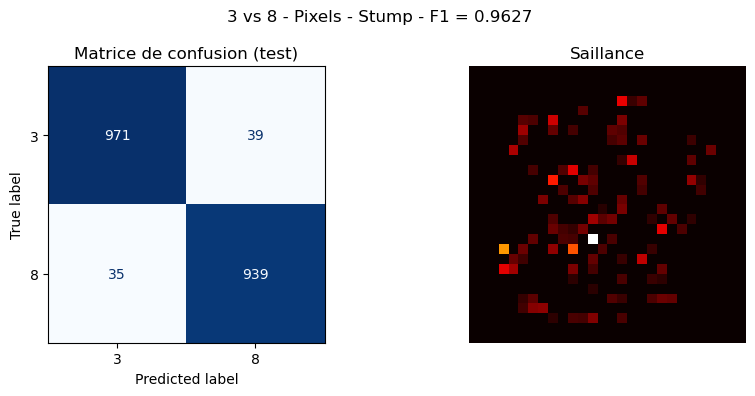

In [28]:
stump_38 = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                              n_estimators=200, random_state=random_seed)
stump_38.fit(X38_train, y38_train)
f1_38["Pixels - Stump"] = afficher_resultats(stump_38, X38_test, y38_test, ["3", "8"], "3 vs 8 - Pixels - Stump")
modeles_38["Pixels - Stump"] = stump_38

### arbres de décisions


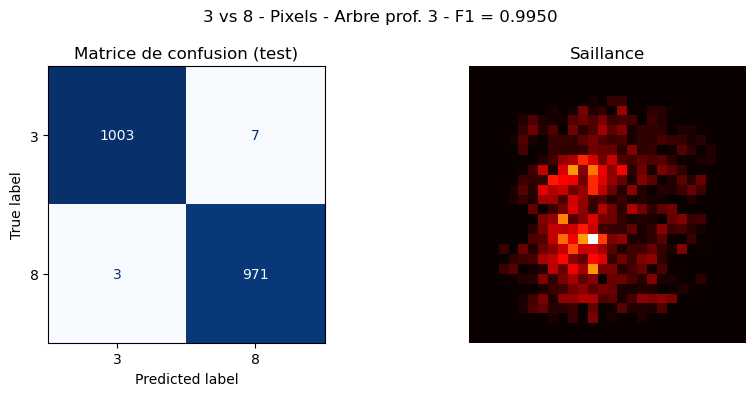

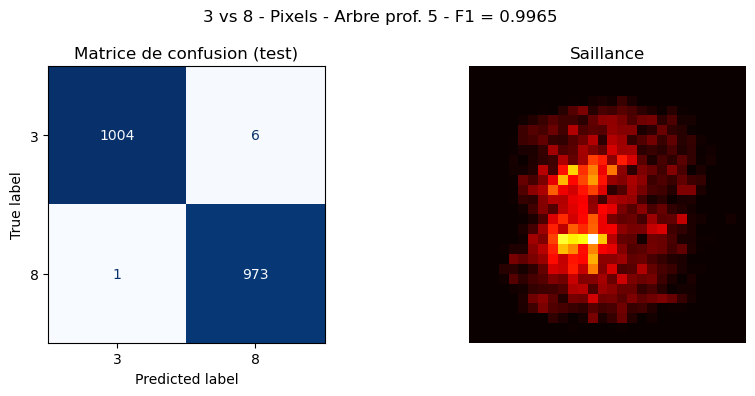

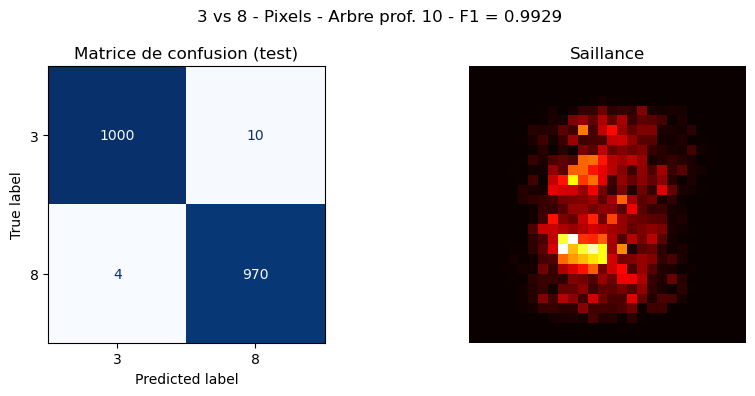

In [29]:
for prof in [3, 5, 10]:
    arbre_38 = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=prof),
                                  n_estimators=200, random_state=random_seed)
    arbre_38.fit(X38_train, y38_train)
    f1_38[f"Pixels - Arbre prof. {prof}"] = afficher_resultats(
        arbre_38, X38_test, y38_test, ["3", "8"], f"3 vs 8 - Pixels - Arbre prof. {prof}")
    modeles_38[f"Pixels - Arbre prof. {prof}"] = arbre_38


### perceptron

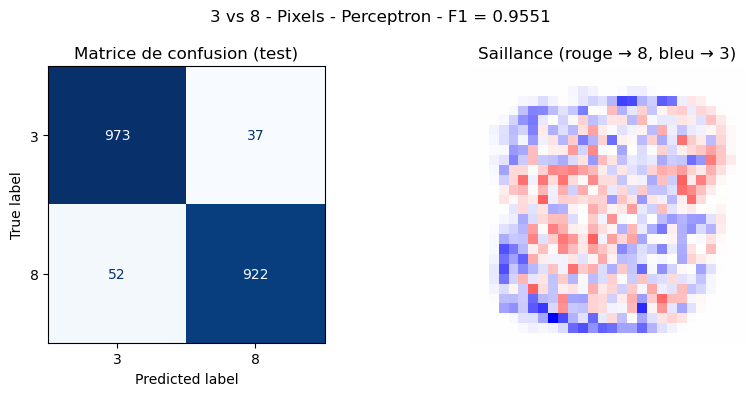

In [30]:
perceptron_38 = AdaBoostClassifier(estimator=Perceptron(random_state=random_seed),
                                   n_estimators=200, random_state=random_seed)
perceptron_38.fit(X38_train, y38_train)
f1_38["Pixels - Perceptron"] = afficher_resultats(perceptron_38, X38_test, y38_test, ["3", "8"], "3 vs 8 - Pixels - Perceptron")
modeles_38["Pixels - Perceptron"] = perceptron_38

## Utilisation de l'embedding



In [19]:
# Calcul de l'embedding pour les images 3 et 8
Z38_train = Ztrain[idx_train]
Z38_test = Ztest[idx_test]
print(Z38_train.shape, Z38_test.shape)


(11982, 64) (1984, 64)


### Decision stump

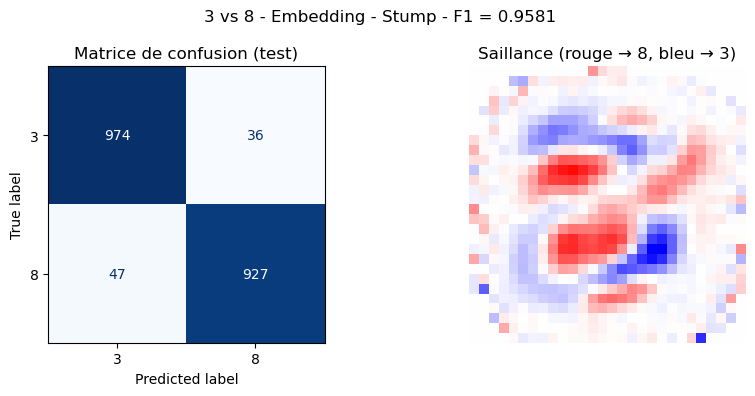

In [24]:
stump_38_emb = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                  n_estimators=200, random_state=random_seed)
stump_38_emb.fit(Z38_train, y38_train)
modeles_38["Embedding - Stump"] = stump_38_emb
f1_38["Embedding - Stump"] = afficher_resultats_embedding(
    stump_38_emb, Z38_train, y38_train, Z38_test, y38_test, X38_test, ["3", "8"], "3 vs 8 - Embedding - Stump")


### arbres de décisions

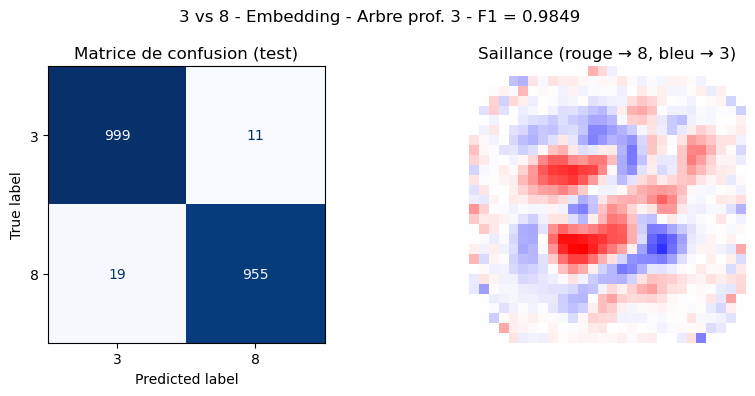

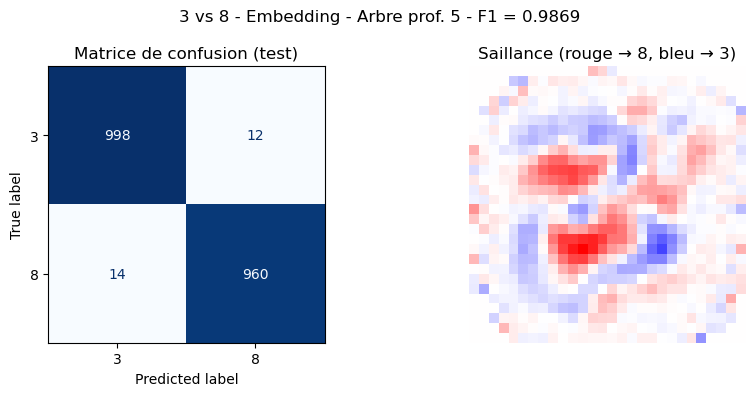

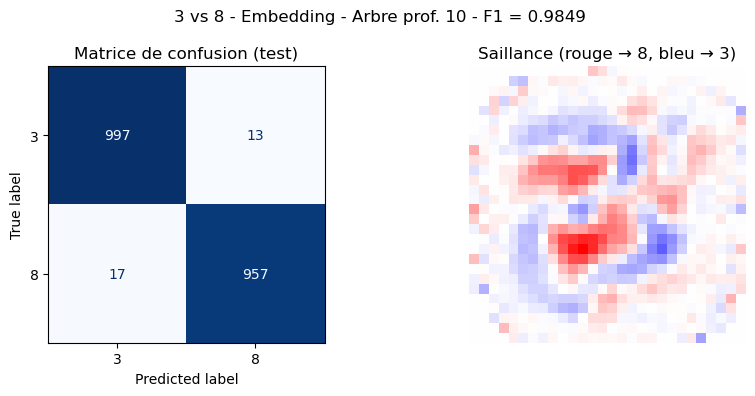

In [25]:
for prof in [3, 5, 10]:
    arbre_38_emb = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=prof),
                                      n_estimators=200, random_state=random_seed)
    arbre_38_emb.fit(Z38_train, y38_train)
    modeles_38[f"Embedding - Arbre prof. {prof}"] = arbre_38_emb
    f1_38[f"Embedding - Arbre prof. {prof}"] = afficher_resultats_embedding(
        arbre_38_emb, Z38_train, y38_train, Z38_test, y38_test, X38_test, ["3", "8"],
        f"3 vs 8 - Embedding - Arbre prof. {prof}")


### Perceptron

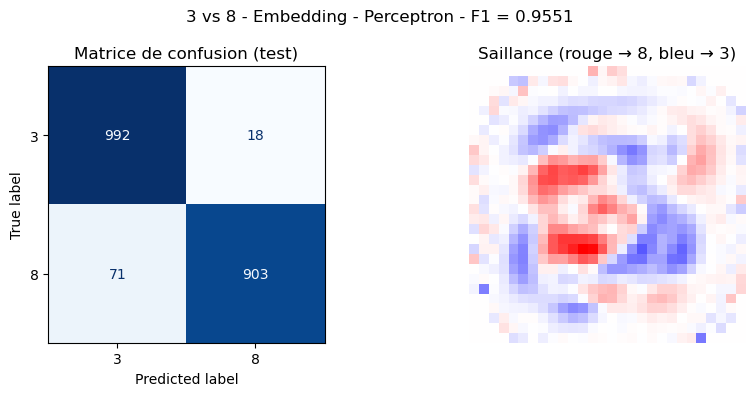

In [26]:
perceptron_38_emb = AdaBoostClassifier(estimator=Perceptron(random_state=random_seed),
                                       n_estimators=200, random_state=random_seed)
perceptron_38_emb.fit(Z38_train, y38_train)
modeles_38["Embedding - Perceptron"] = perceptron_38_emb
f1_38["Embedding - Perceptron"] = afficher_resultats_embedding(
    perceptron_38_emb, Z38_train, y38_train, Z38_test, y38_test, X38_test, ["3", "8"], "3 vs 8 - Embedding - Perceptron")


## Bilan de la section 3 vs 8

Embedding - Stump              F1 = 0.9581
Embedding - Arbre prof. 3      F1 = 0.9849
Embedding - Arbre prof. 5      F1 = 0.9869
Embedding - Arbre prof. 10     F1 = 0.9849
Embedding - Perceptron         F1 = 0.9551
Pixels - Stump                 F1 = 0.9627
Pixels - Arbre prof. 3         F1 = 0.9950
Pixels - Arbre prof. 5         F1 = 0.9965
Pixels - Arbre prof. 10        F1 = 0.9929
Pixels - Perceptron            F1 = 0.9551


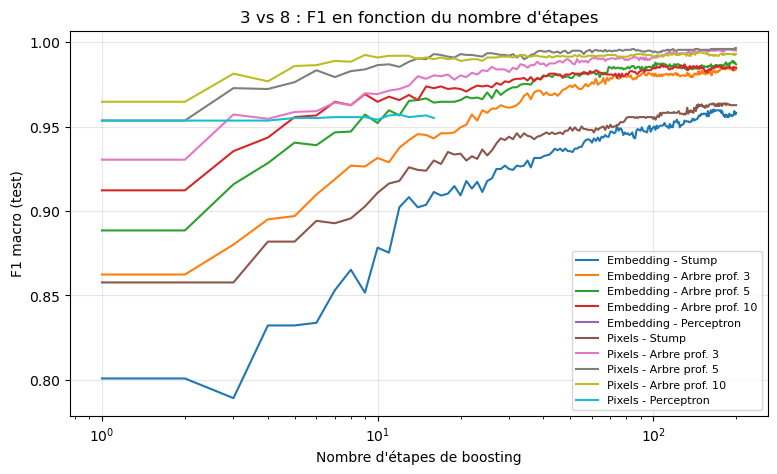

In [31]:
# F1 final de chaque modèle
for nom, f1 in f1_38.items():
    print(f"{nom:30s} F1 = {f1:.4f}")

# Courbe du F1 (test) en fonction du nombre d'étapes de boosting
plt.figure(figsize=(9, 5))
for nom, modele in modeles_38.items():
    X_eval = Z38_test if nom.startswith("Embedding") else X38_test
    f1_etapes = [f1_score(y38_test, pred, average="macro") for pred in modele.staged_predict(X_eval)]

    plt.plot(range(1, len(f1_etapes) + 1), f1_etapes, label=nom)
plt.xscale("log")
plt.xlabel("Nombre d'étapes de boosting")
plt.ylabel("F1 macro (test)")
plt.title("3 vs 8 : F1 en fonction du nombre d'étapes")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.show()


**Comparaisons du boosting sur les classifieurs faibles** 

On observe que les arbres de décisions de profondeurs 3, 5 et 10 sont les classifieurs faibles qui permettent d'obtenir les meilleurs performances. On observe que les arbres les plus complexes permettent d'obtenir de meilleures performances rapidemment mais qu'après 200 étapes de boosting, les 3 classifieurs sont équivalents.

On observe que quand on utilise le perceptron, le bossting s'arrête au bout de 15 étapes et ne va pas jusqu'au bout : le boosting ne permet plus d'améliorer les performances. Lorsqu'on utilise l'embedding, on observe d'ailleurs que le boosting s'arrête dès l'étape 1. Le perceptron semble donc être une classifieur trop "fort".

Les stumps sont les modèles offrant les moins bonnes performances.

**Comparaisons des résultats avec et sans embedding**

On observe que l'embedding ne permet pas d'atteindre le même palier que lorsqu'on utilise les images brutes.

**Analyse des cartes de saillances**

Sur le stump sur les pixels, on observes quelques pixels isolés majoritairement au centre, à gauche et à droite. On peut émettre l'hypothèse que ce sont les pixels qui permettent de repérer si le double boucle du trois et du huit est ouverte ou fermé.
Pour les arbres et le perceptron, la tache est plus diffuse.

Lorsqu'on a fait l'embedding, les cartes de saillances sont toutes très similaires. On peut donc émettre l'hypothèse que cela est plus lié à la méthode d'embedding qu'à l'architecture du modèle.


# 4. Classification des 1 vs 7
## Image brute



In [38]:
# Sélection des 1 et des 7 dans les données d'entraînement et de test, pour une tâche binaire
idx_train = (Ytrain == 1) | (Ytrain == 7)
idx_test = (Ytest == 1) | (Ytest == 7)

X17_train, y17_train = Xtrain[idx_train], (Ytrain[idx_train] == 7).astype(int)
X17_test, y17_test = Xtest[idx_test], (Ytest[idx_test] == 7).astype(int)

f1_17 = {}   # F1 de chaque modèle, pour le bilan
modeles_17 = {}   # modèles entraînés, pour les courbes du bilan

print(X17_train.shape, X17_test.shape)


(13007, 784) (2163, 784)




### Decision stump


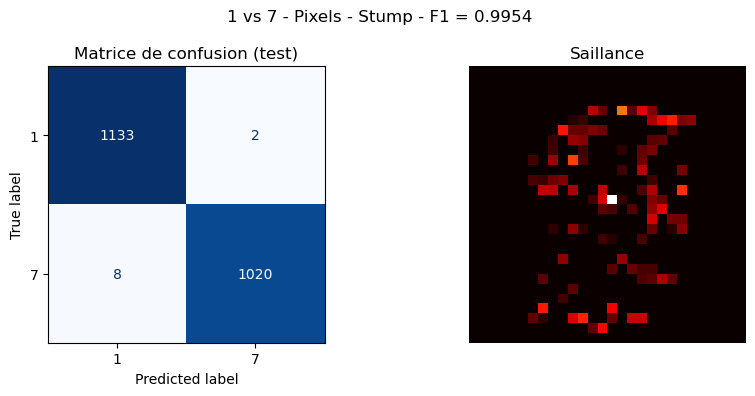

In [40]:
stump_17 = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                              n_estimators=200, random_state=random_seed)
stump_17.fit(X17_train, y17_train)
f1_17["Pixels - Stump"] = afficher_resultats(stump_17, X17_test, y17_test, ["1", "7"], "1 vs 7 - Pixels - Stump")
modeles_17["Pixels - Stump"] = stump_17


### arbres de décisions



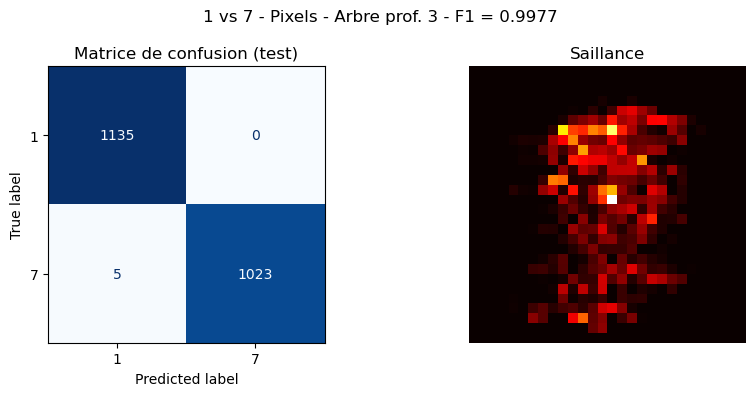

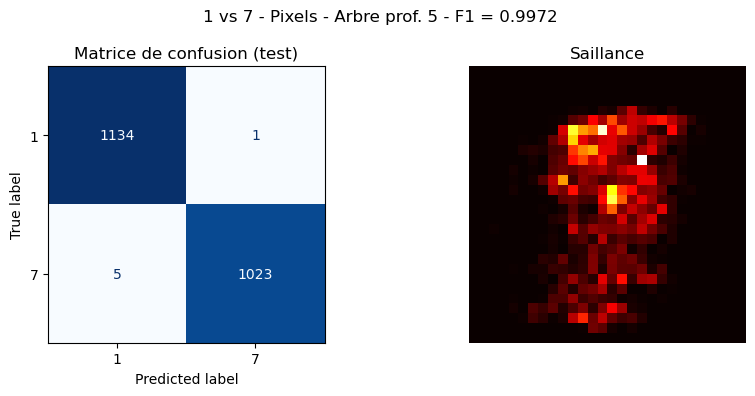

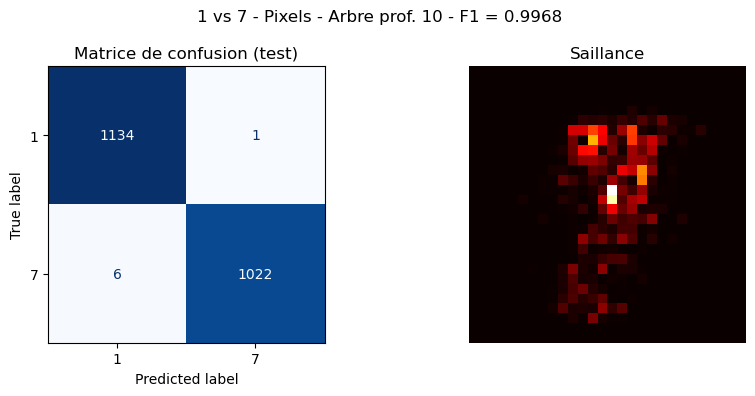

In [41]:
for prof in [3, 5, 10]:
    arbre_17 = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=prof),
                                  n_estimators=200, random_state=random_seed)
    arbre_17.fit(X17_train, y17_train)
    f1_17[f"Pixels - Arbre prof. {prof}"] = afficher_resultats(
        arbre_17, X17_test, y17_test, ["1", "7"], f"1 vs 7 - Pixels - Arbre prof. {prof}")
    modeles_17[f"Pixels - Arbre prof. {prof}"] = arbre_17


### perceptron




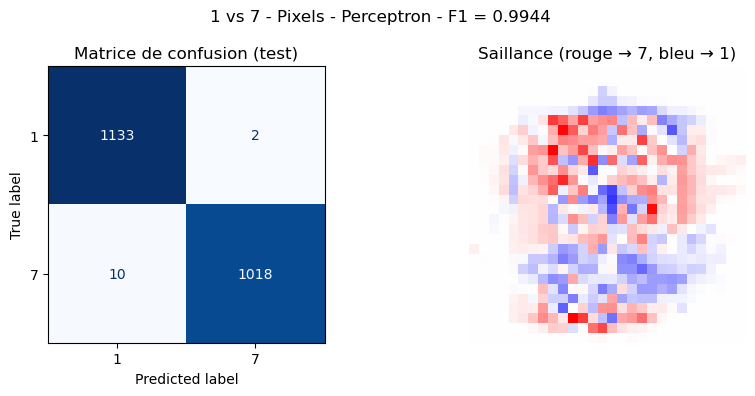

In [42]:
perceptron_17 = AdaBoostClassifier(estimator=Perceptron(random_state=random_seed),
                                   n_estimators=200, random_state=random_seed)
perceptron_17.fit(X17_train, y17_train)
f1_17["Pixels - Perceptron"] = afficher_resultats(perceptron_17, X17_test, y17_test, ["1", "7"], "1 vs 7 - Pixels - Perceptron")
modeles_17["Pixels - Perceptron"] = perceptron_17


## Utilisation de l'embedding




In [43]:
# Calcul de l'embedding pour les images 1 et 7
Z17_train = Ztrain[idx_train]
Z17_test = Ztest[idx_test]
print(Z17_train.shape, Z17_test.shape)


(13007, 64) (2163, 64)


### Decision stump

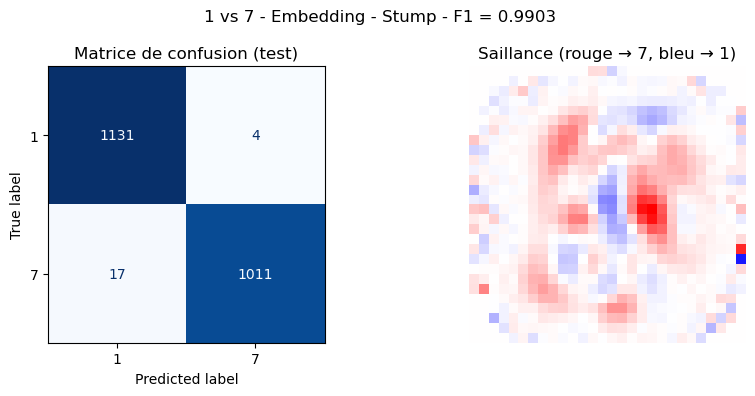

In [44]:
stump_17_emb = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                  n_estimators=200, random_state=random_seed)
stump_17_emb.fit(Z17_train, y17_train)
modeles_17["Embedding - Stump"] = stump_17_emb
f1_17["Embedding - Stump"] = afficher_resultats_embedding(
    stump_17_emb, Z17_train, y17_train, Z17_test, y17_test, X17_test, ["1", "7"], "1 vs 7 - Embedding - Stump")


### arbres de décisions


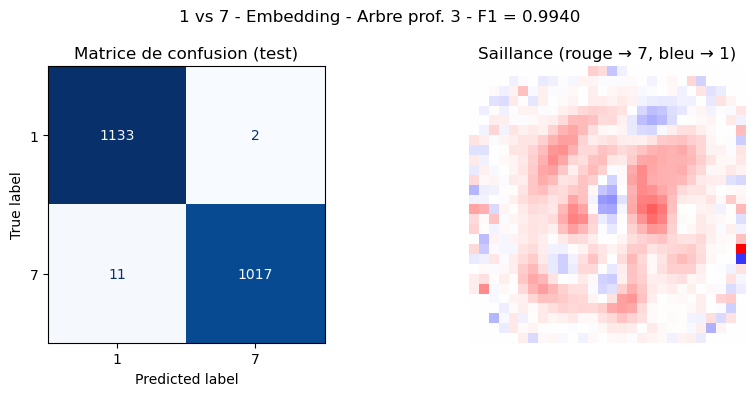

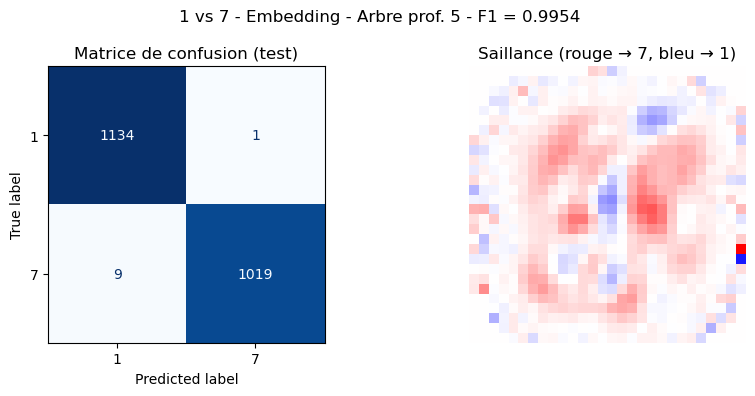

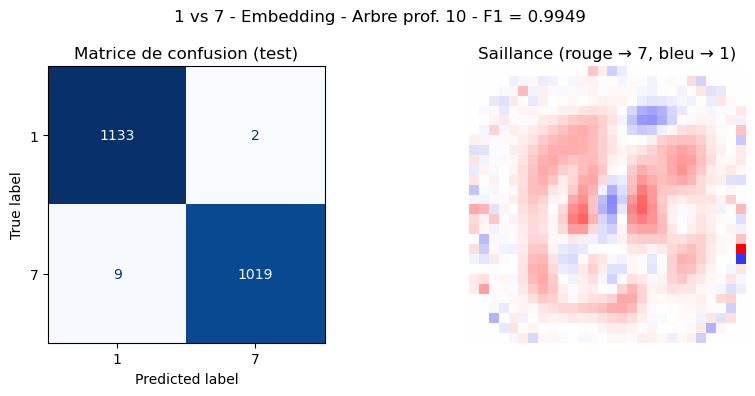

In [45]:
for prof in [3, 5, 10]:
    arbre_17_emb = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=prof),
                                      n_estimators=200, random_state=random_seed)
    arbre_17_emb.fit(Z17_train, y17_train)
    modeles_17[f"Embedding - Arbre prof. {prof}"] = arbre_17_emb
    f1_17[f"Embedding - Arbre prof. {prof}"] = afficher_resultats_embedding(
        arbre_17_emb, Z17_train, y17_train, Z17_test, y17_test, X17_test, ["1", "7"],
        f"1 vs 7 - Embedding - Arbre prof. {prof}")


### perceptron



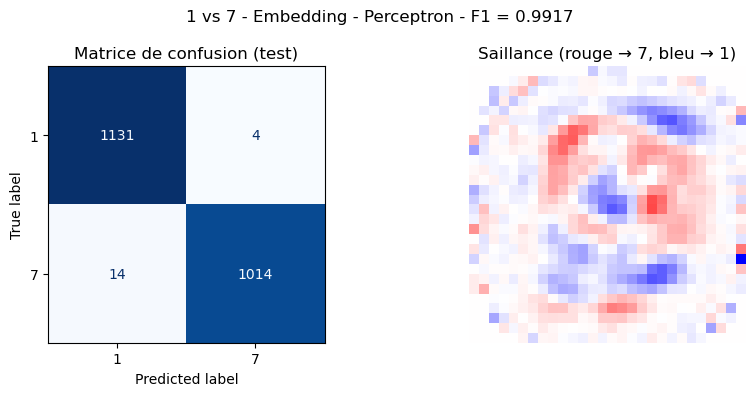

In [46]:
perceptron_17_emb = AdaBoostClassifier(estimator=Perceptron(random_state=random_seed),
                                       n_estimators=200, random_state=random_seed)
perceptron_17_emb.fit(Z17_train, y17_train)
modeles_17["Embedding - Perceptron"] = perceptron_17_emb
f1_17["Embedding - Perceptron"] = afficher_resultats_embedding(
    perceptron_17_emb, Z17_train, y17_train, Z17_test, y17_test, X17_test, ["1", "7"], "1 vs 7 - Embedding - Perceptron")


## Bilan

Pixels - Stump                 F1 = 0.9954
Pixels - Arbre prof. 3         F1 = 0.9977
Pixels - Arbre prof. 5         F1 = 0.9972
Pixels - Arbre prof. 10        F1 = 0.9968
Pixels - Perceptron            F1 = 0.9944
Embedding - Stump              F1 = 0.9903
Embedding - Arbre prof. 3      F1 = 0.9940
Embedding - Arbre prof. 5      F1 = 0.9954
Embedding - Arbre prof. 10     F1 = 0.9949
Embedding - Perceptron         F1 = 0.9917


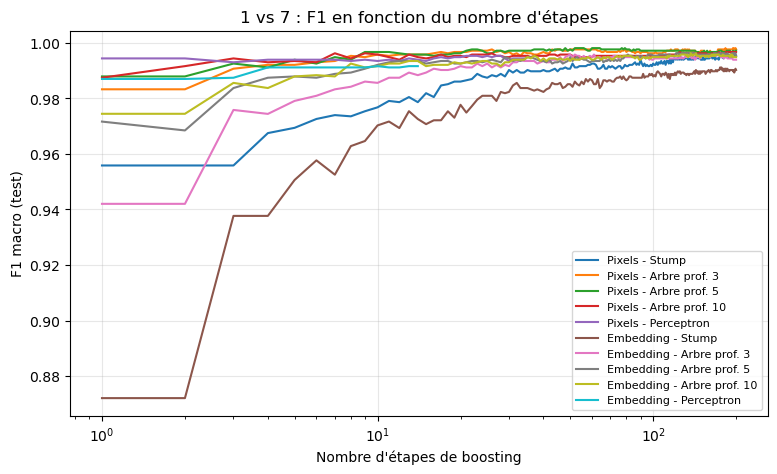

In [47]:
# F1 final de chaque modèle
for nom, f1 in f1_17.items():
    print(f"{nom:30s} F1 = {f1:.4f}")

# Courbe du F1 (test) en fonction du nombre d'étapes de boosting
plt.figure(figsize=(9, 5))
for nom, modele in modeles_17.items():
    X_eval = Z17_test if nom.startswith("Embedding") else X17_test
    f1_etapes = [f1_score(y17_test, pred, average="macro") for pred in modele.staged_predict(X_eval)]

    plt.plot(range(1, len(f1_etapes) + 1), f1_etapes, label=nom)
plt.xscale("log")
plt.xlabel("Nombre d'étapes de boosting")
plt.ylabel("F1 macro (test)")
plt.title("1 vs 7 : F1 en fonction du nombre d'étapes")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.show()


On observe globalement les même résultats que pour la classification des 3 vs 8 : 
Le perceptron semble être un classifieur faible trop fort ainsi sur les exemples difficiles mal classé, le perceptron d'après ne fait pas mieux que le hasard.
Les arbres de décisions de faible profondeur (3 et 5) sont ceux qui offrent les meilleures performances.
L'embedding n'améliore pas les performances du modèle.


**Analyse des cartes de saillances**

Sur les pixels, les stumps et les arbres s'appuient surtout sur le haut de l'image, à l'emplacement de la barre horizontale du 7 et sur la barre horizontale du 1, ce qui permet de différencier le 1 du 7.

Dans l'embedding, on retrouve la même logique de façon plus lisse : une bande bleue verticale et étroite au centre (le trait du 1) entourée de zones rouges en haut à gauche et au centre-droit (la barre et la diagonale du 7). Comme pour 3 vs 8, les cartes des trois classifieurs sont très proches, ce qui confirme l'hypothèse que leur forme dépend surtout de l'embedding plutôt que du classifieur faible.


# 5. Résultats globaux calculés

Dans le notebook "etude_complete_toute_paires.ipynb", le même travail a été réalisé sur toutes les combinaisons de paires chiffres possibles. l'objectif de cette section est de présenter et de synthétiser les résultats obtenues.

Cependant certains paramètres différent : la profondeur des arbres diffère, nous avons créé notre propre algorithme adaboost plutôt que d'utiliser le module scikit-learn (cela change juste l'arrêt ou non de l'algorithme de boosting).

Ce notebook doit être exécuter sur une vm en raison de la taille des calculs réalisés.



In [32]:
# Chargement des résultats des 45 paires, calculés dans etude_complete_toute_paires.ipynb
PAIRES = [(a, b) for a in range(10) for b in range(10) if a < b]
ESPACES = ["Pixels", "Embedding"]

resultats_globaux = {f"{a}_{b}": joblib.load(os.path.join("resultats", f"tache_{a}_{b}.joblib"))
                     for a, b in PAIRES}
NOMS_MODELES = list(resultats_globaux["0_1"]["modeles"]["Pixels"])

print(len(resultats_globaux), "paires chargées. Classifieurs :", NOMS_MODELES)


45 paires chargées. Classifieurs : ['Stump', 'Perceptron', 'Arbre prof. 5', 'Arbre prof. 7', 'Arbre prof. 10', 'Arbre prof. 15']


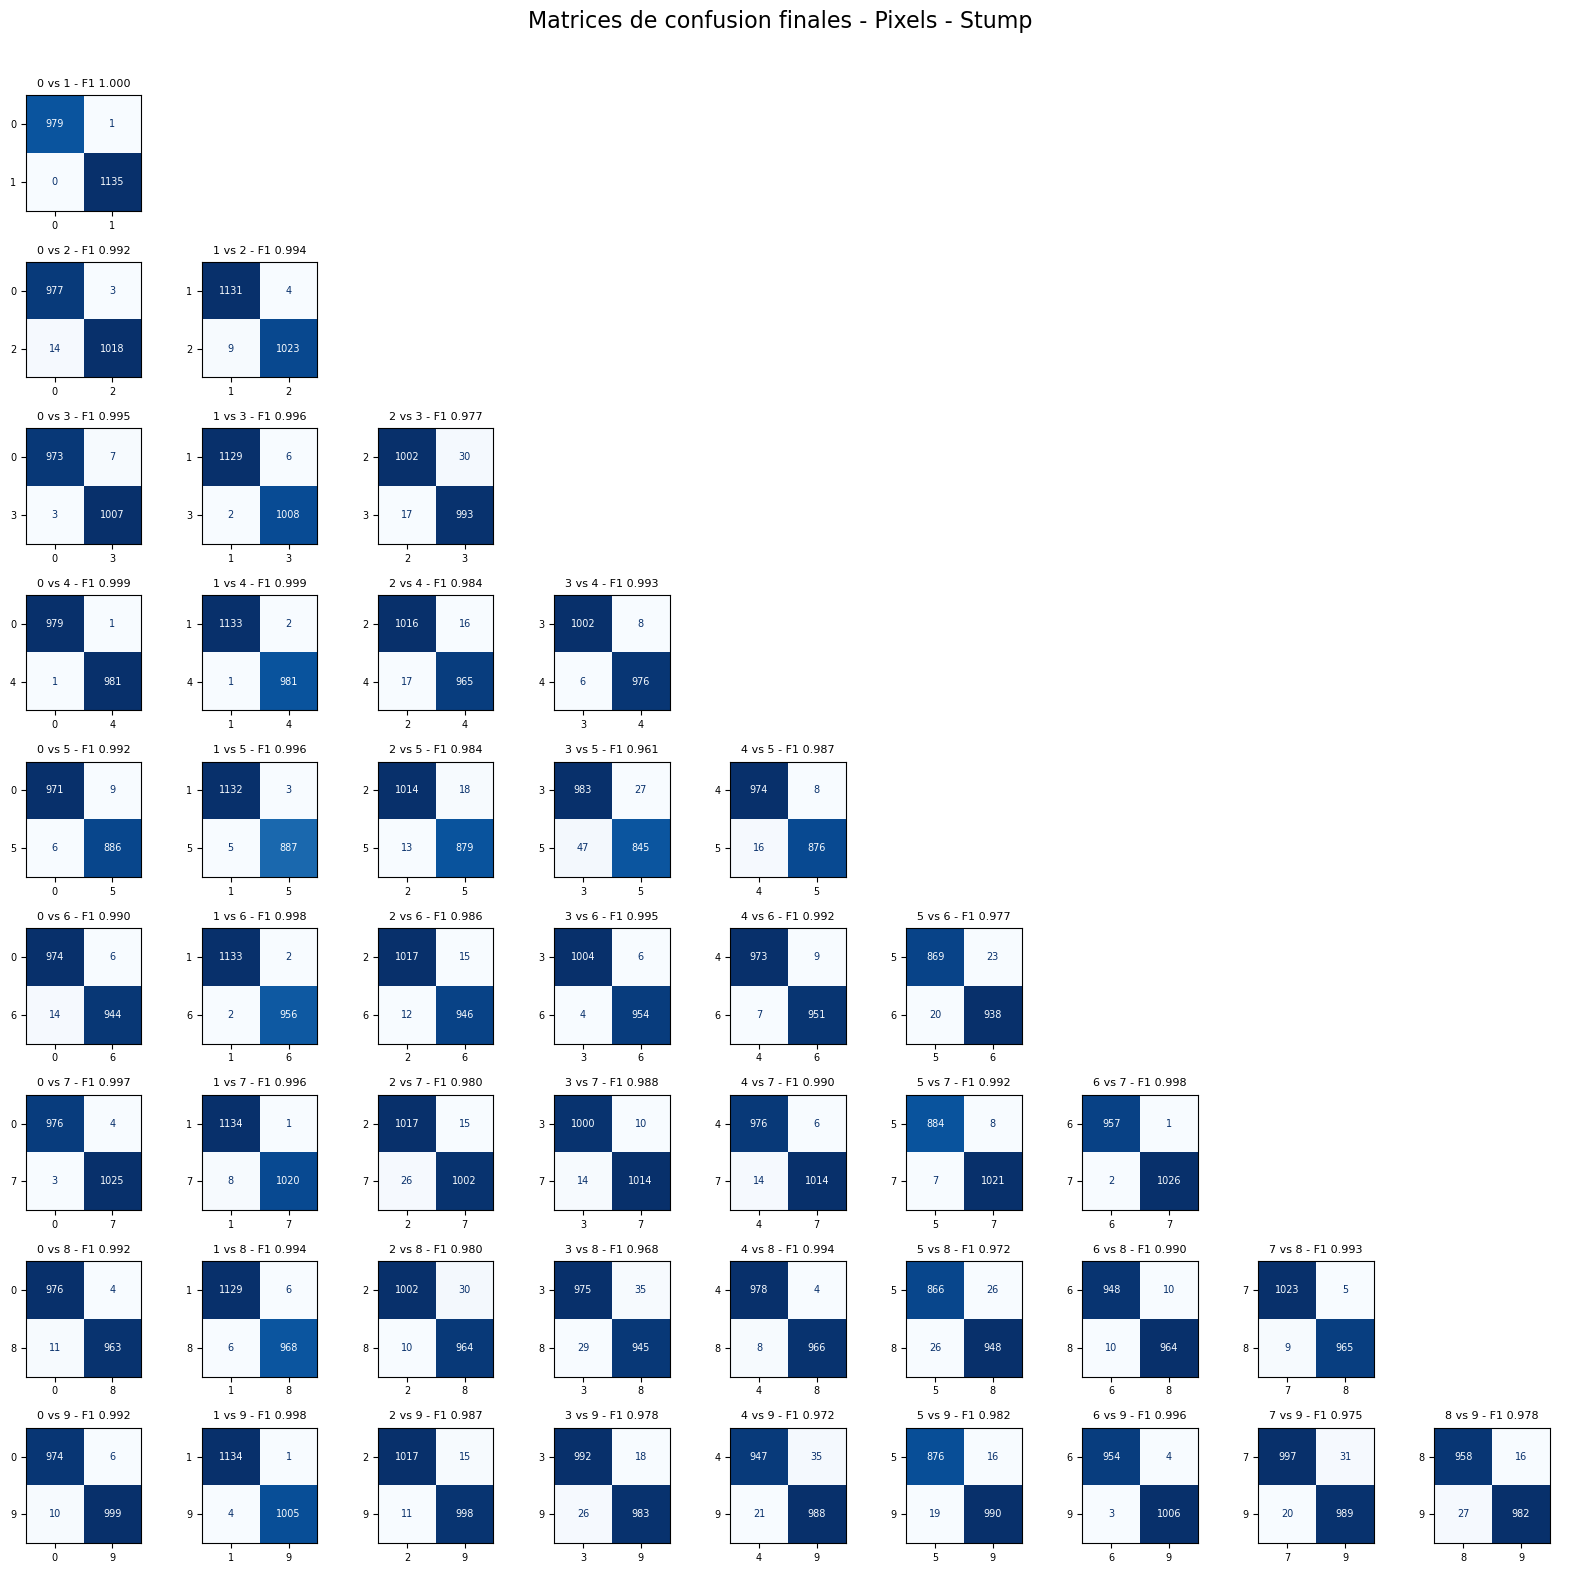

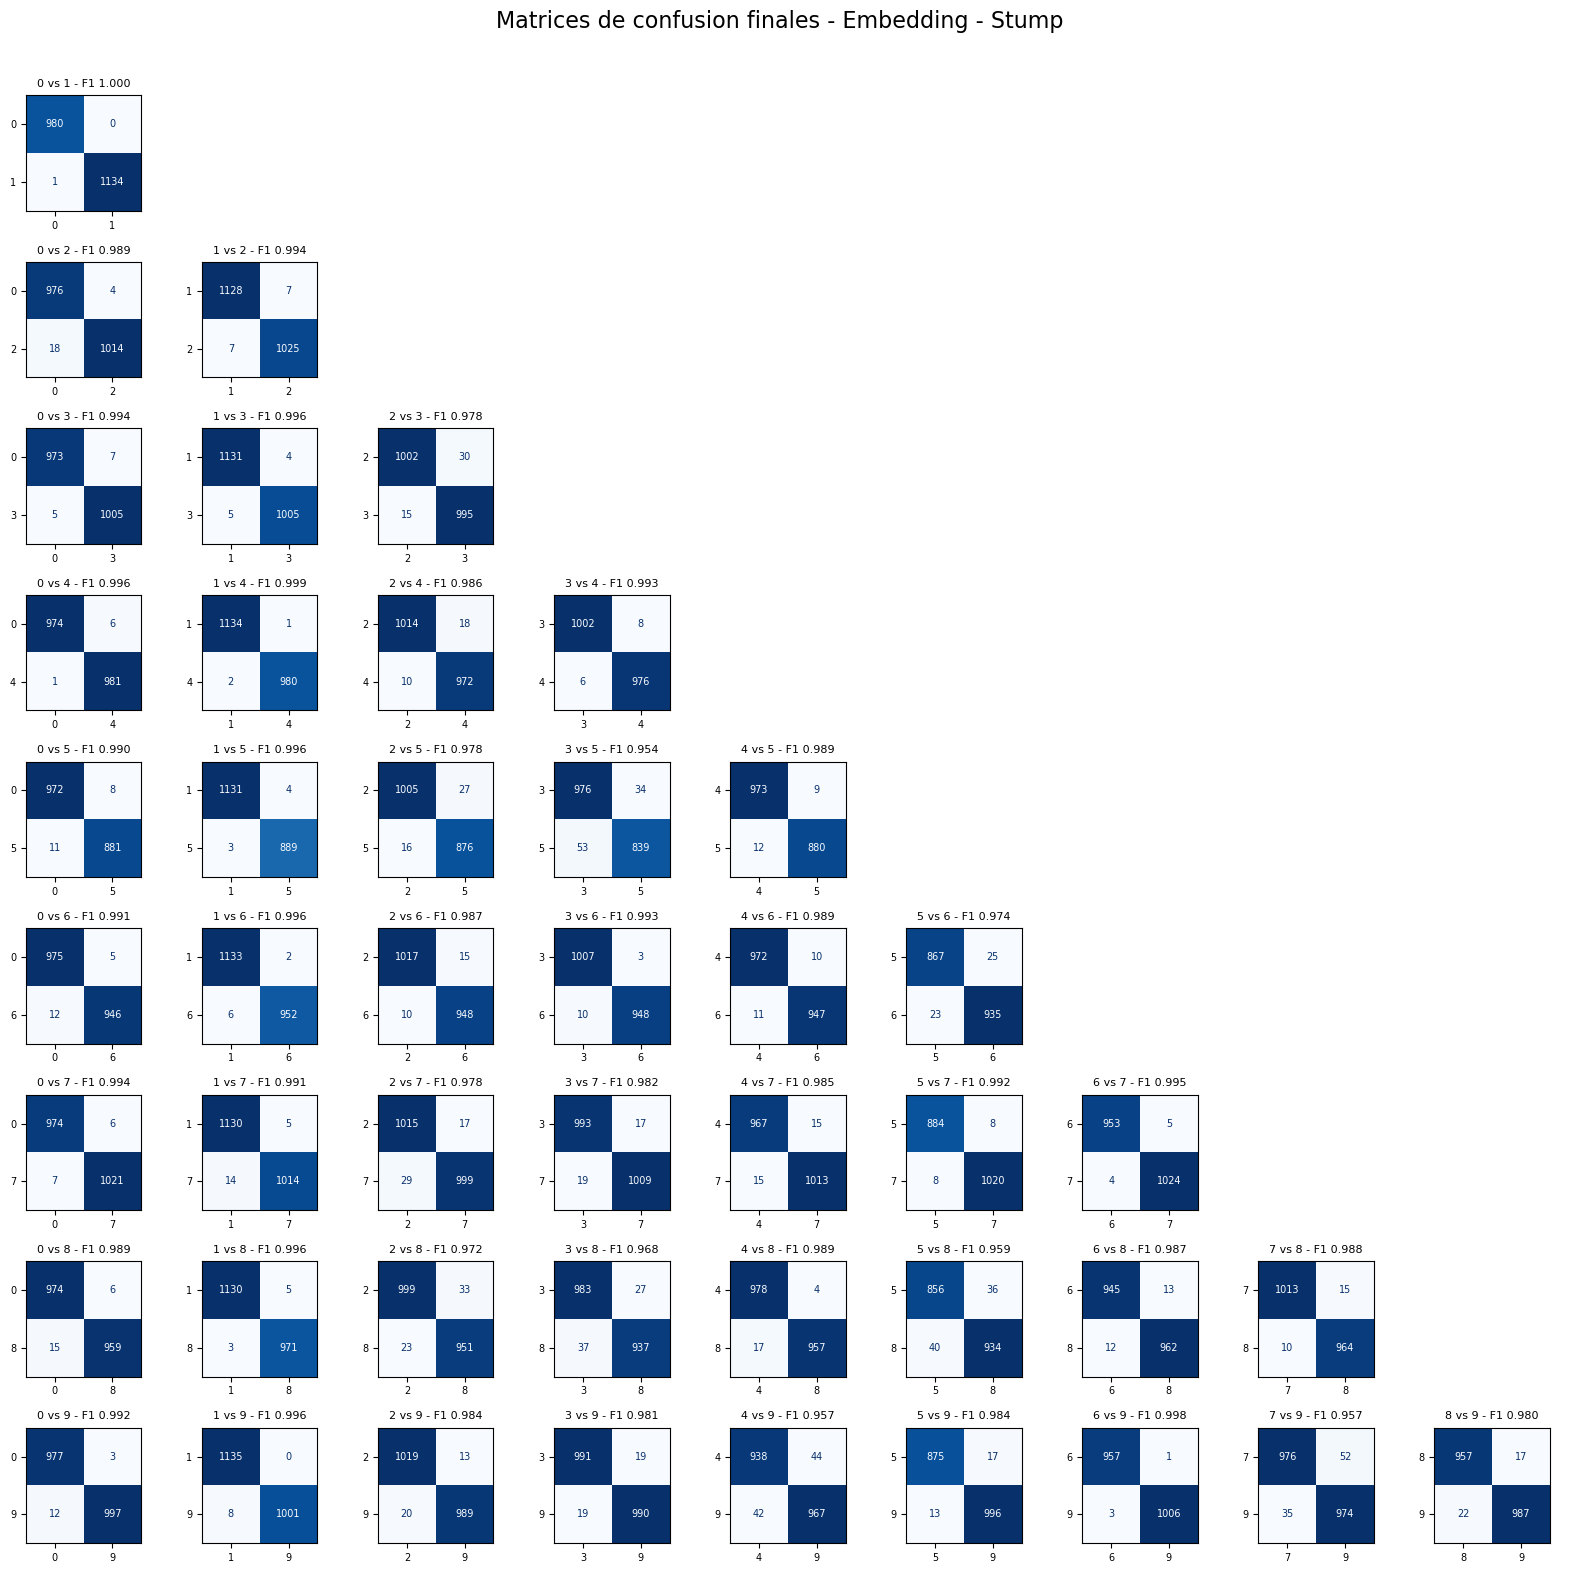

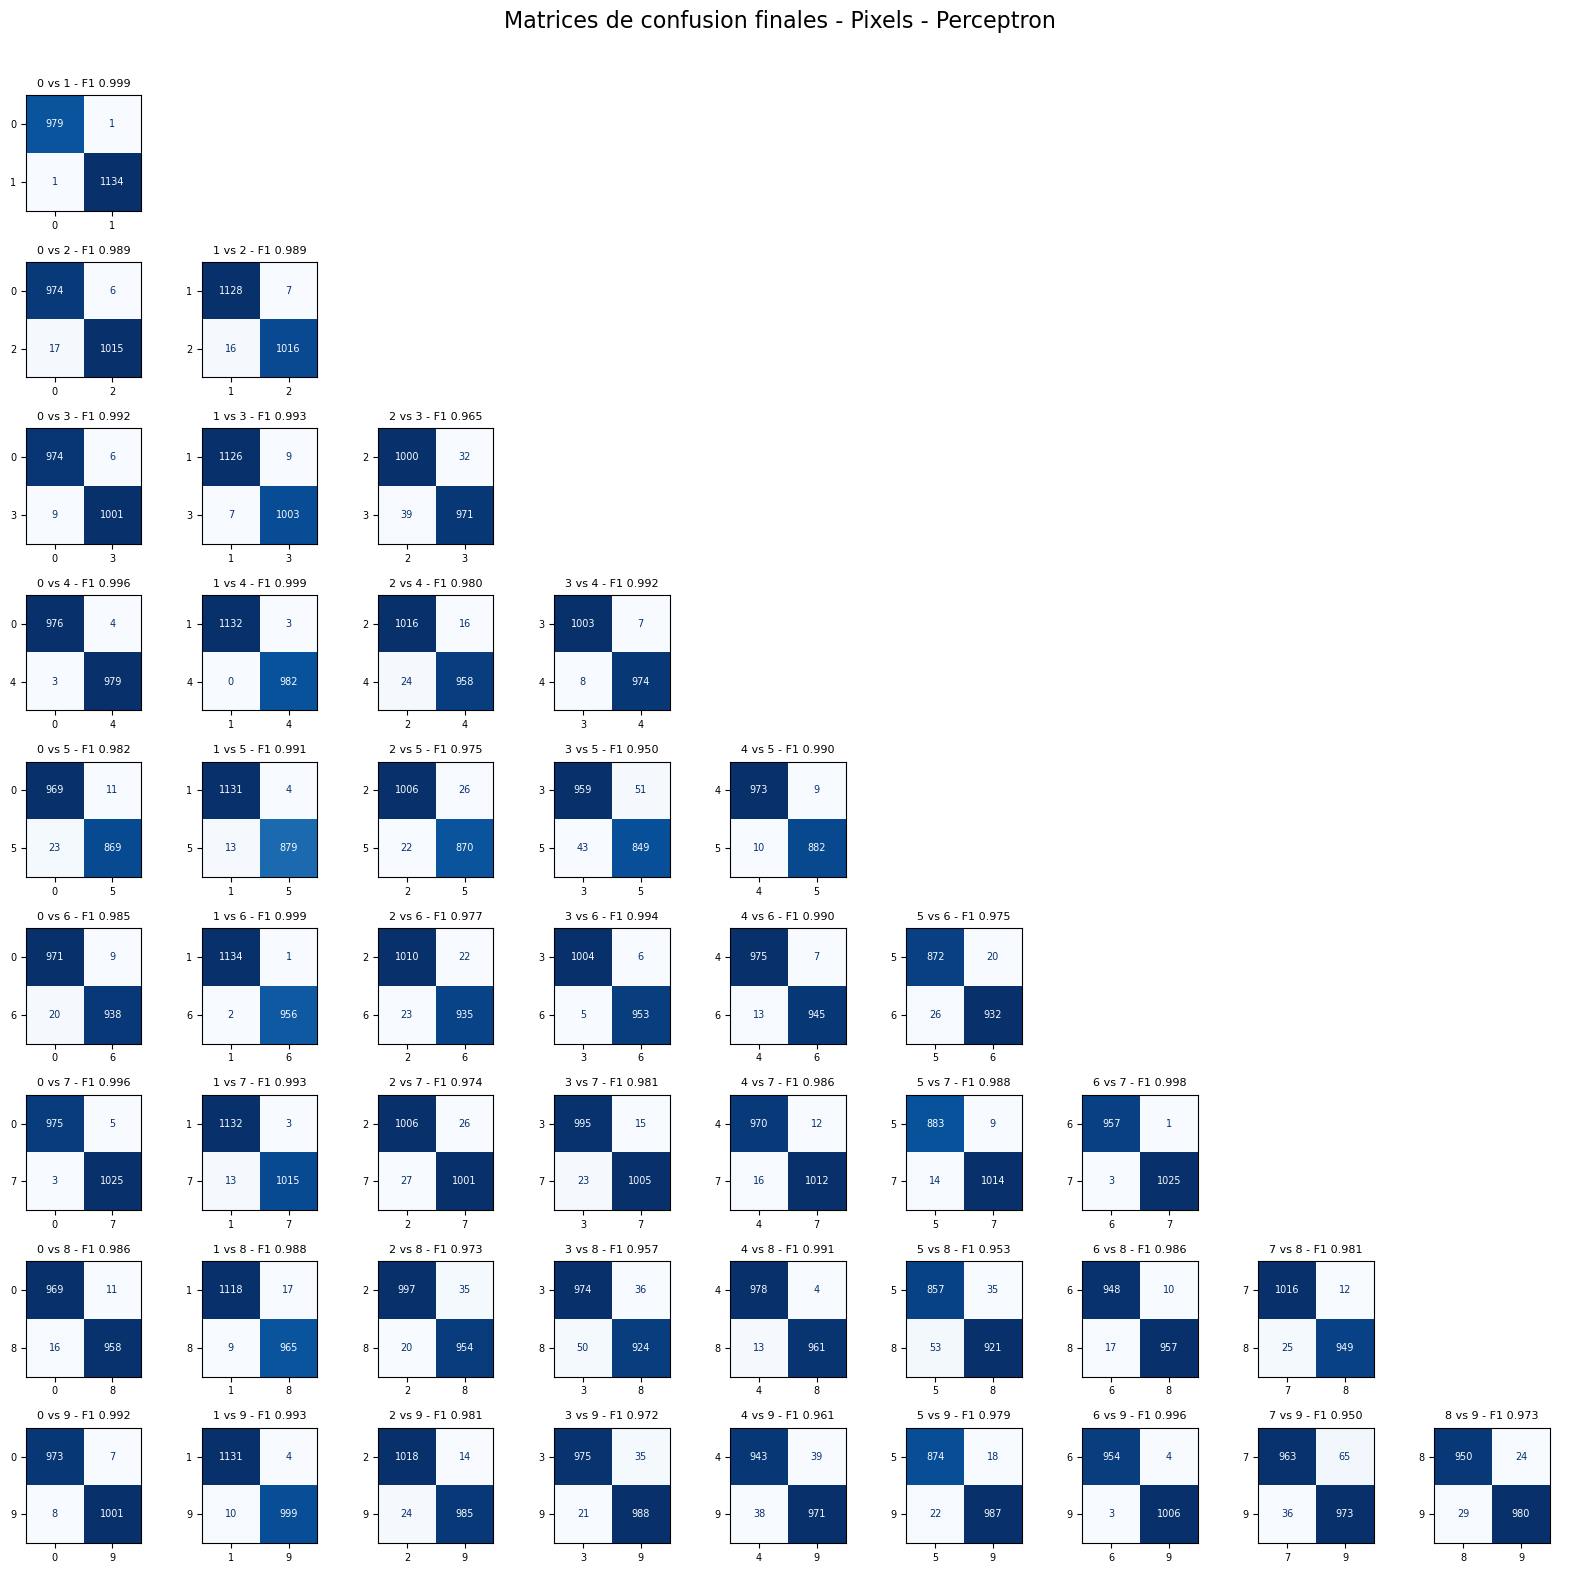

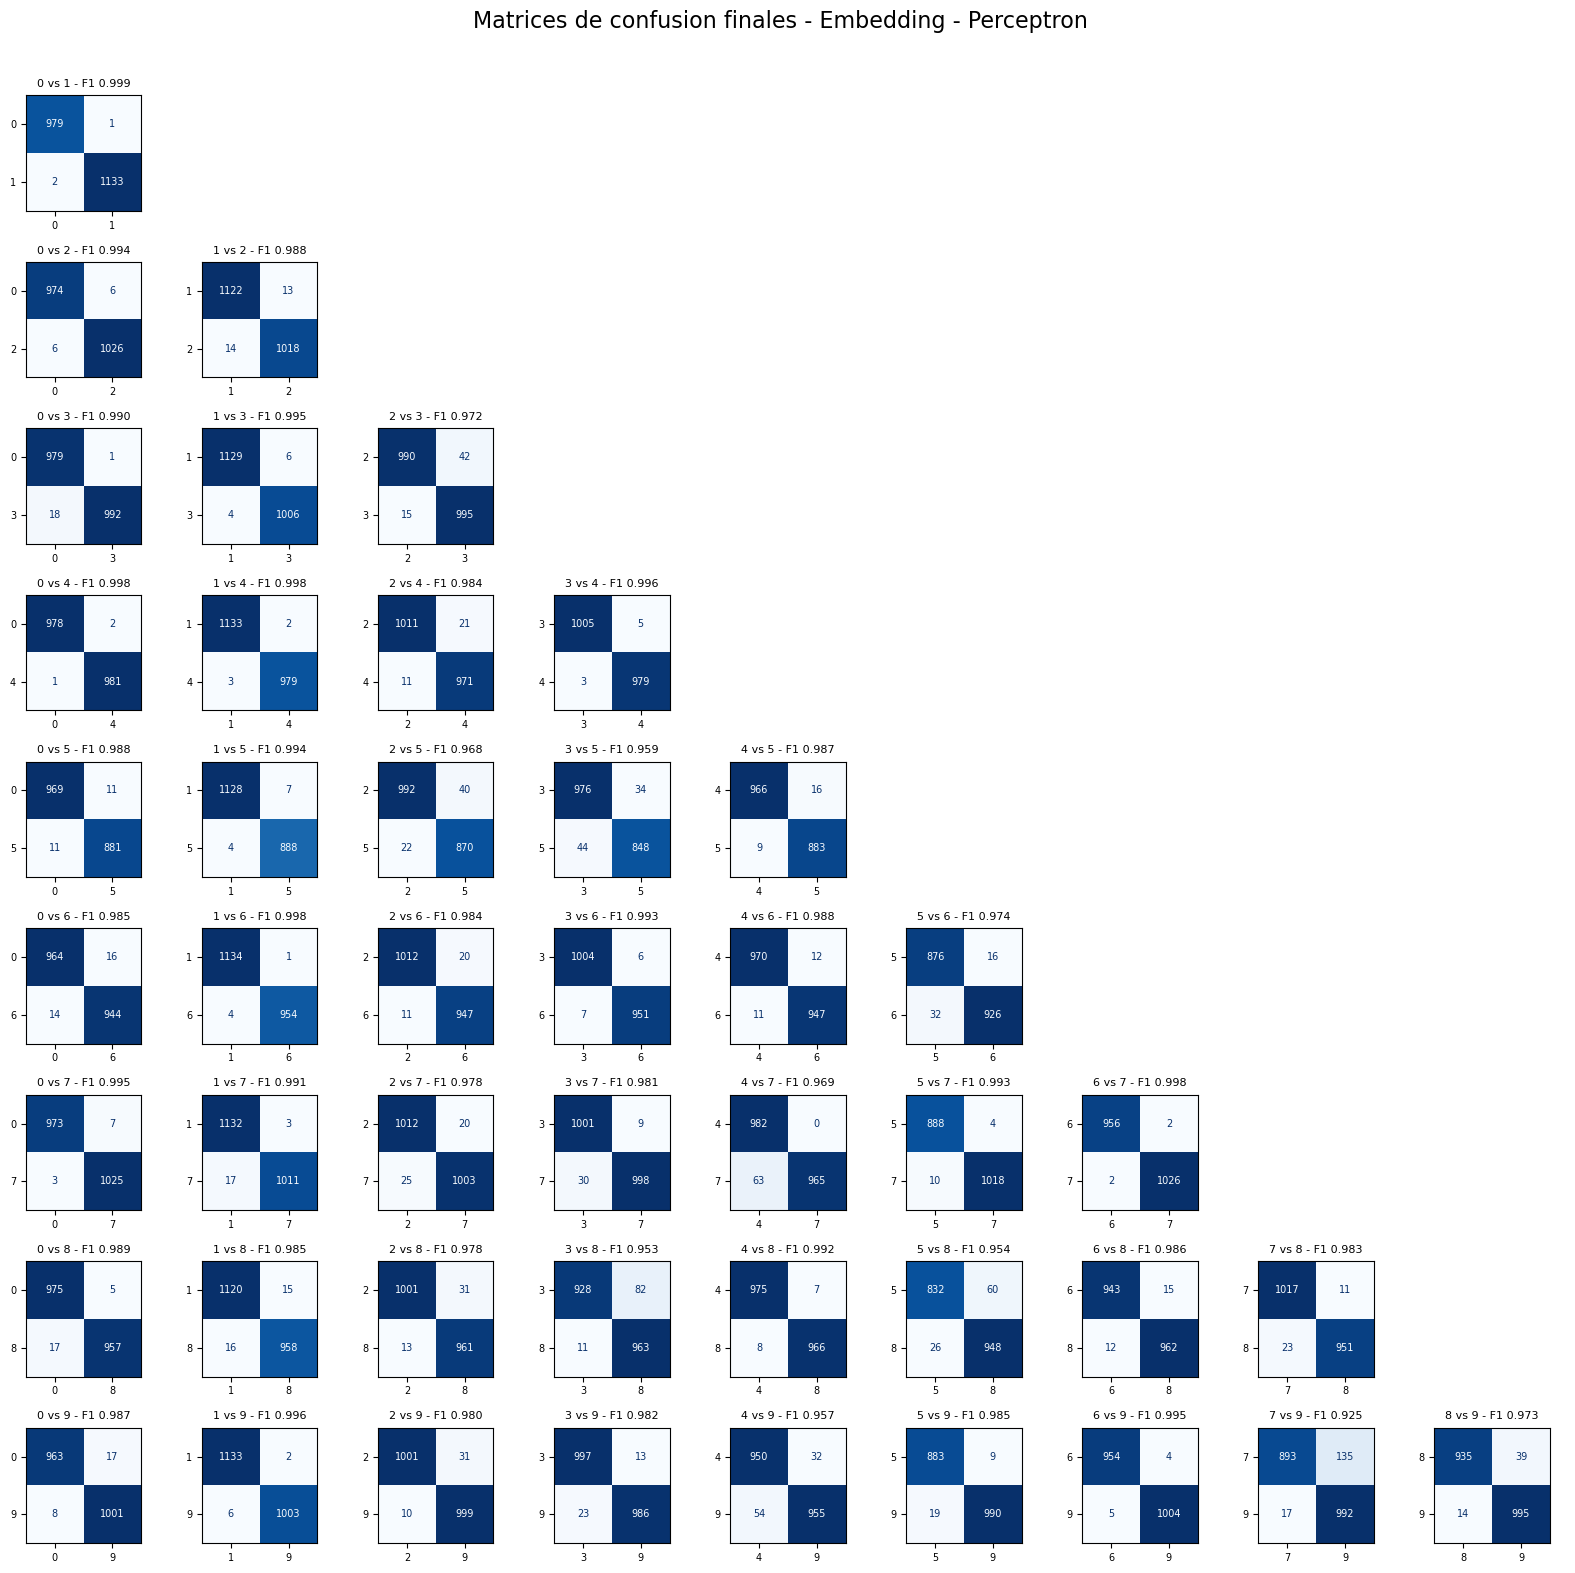

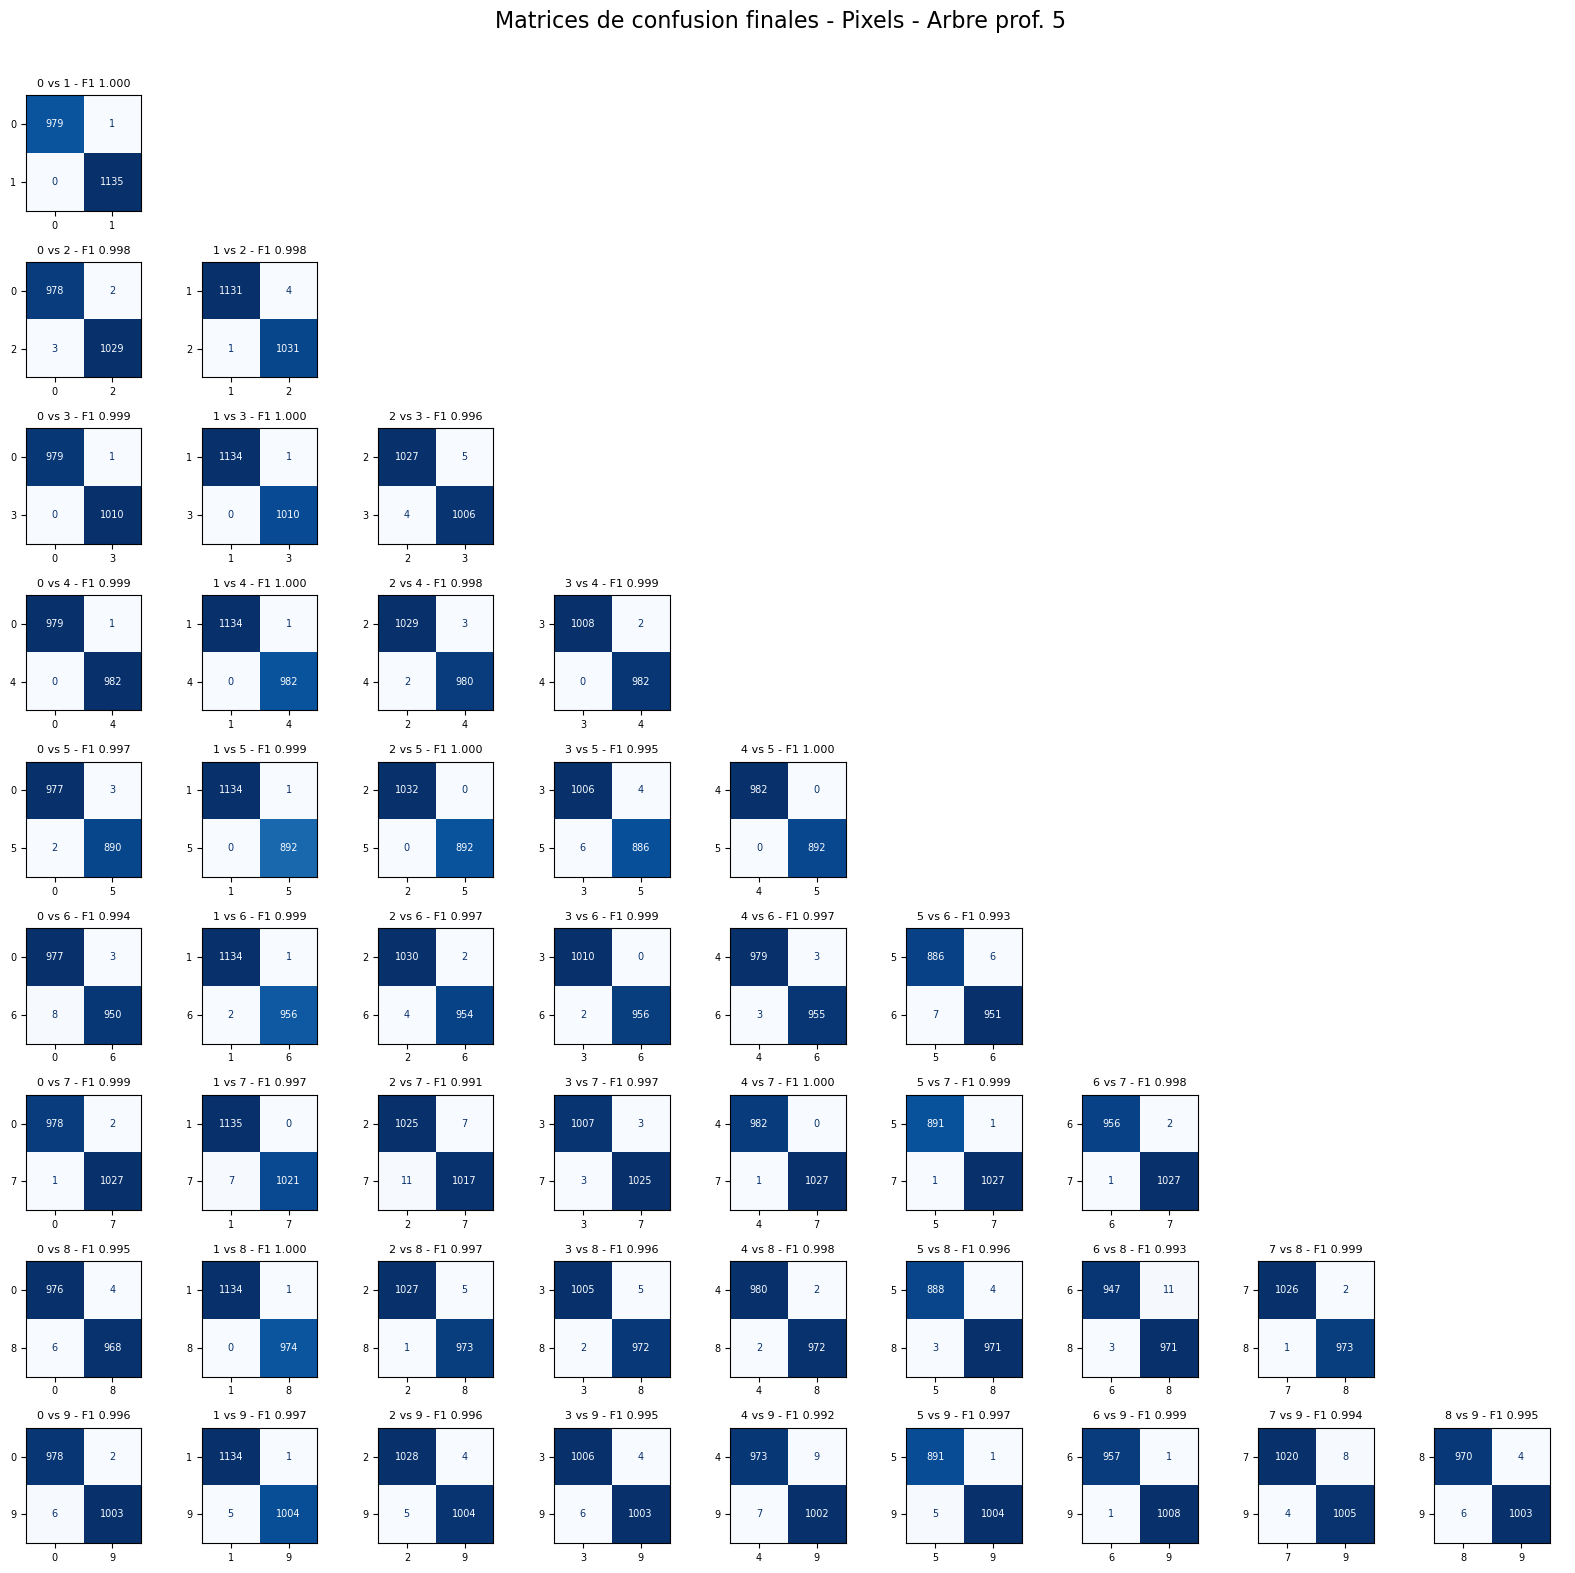

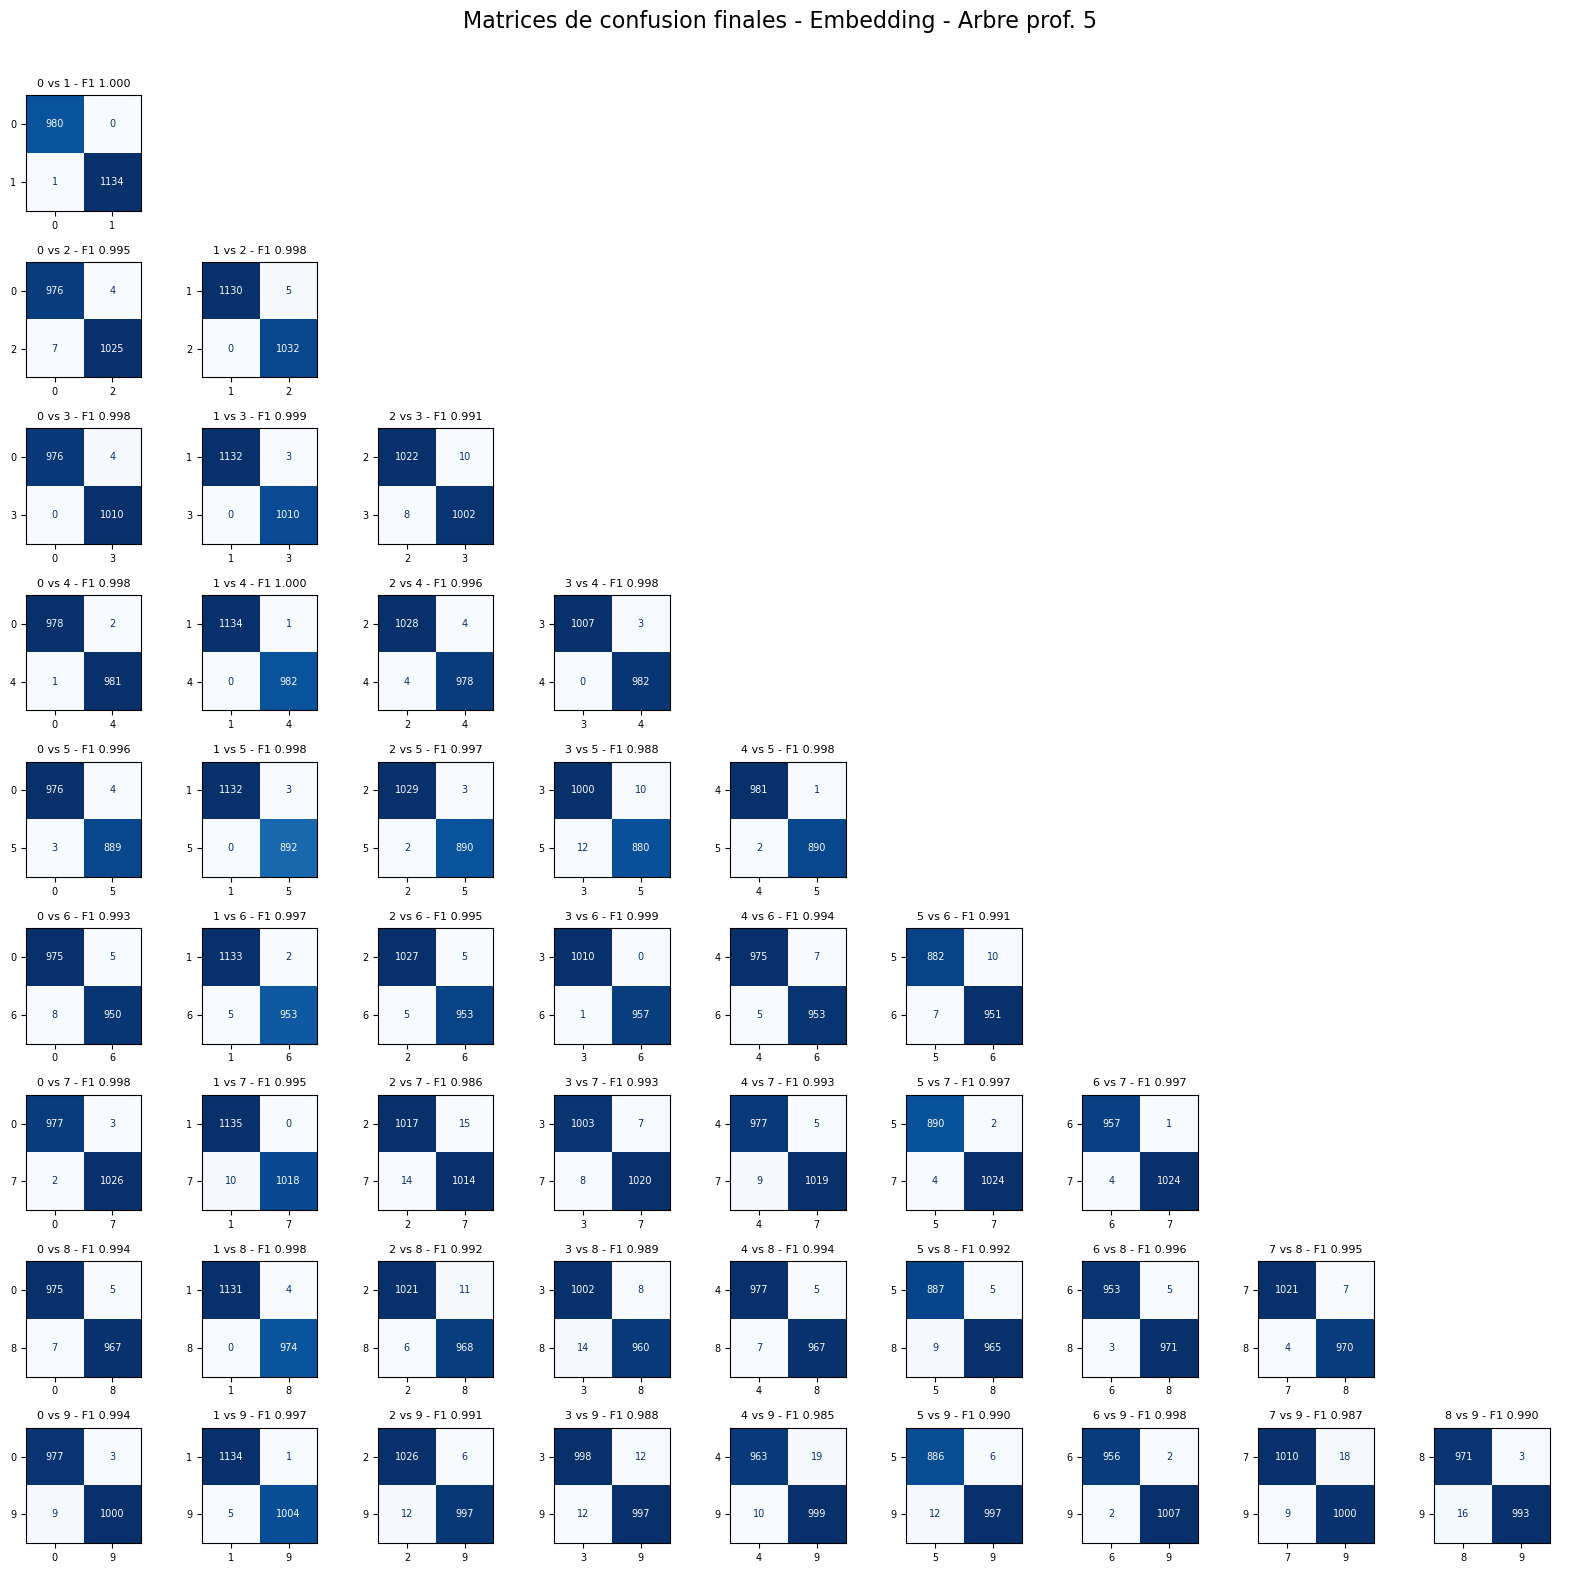

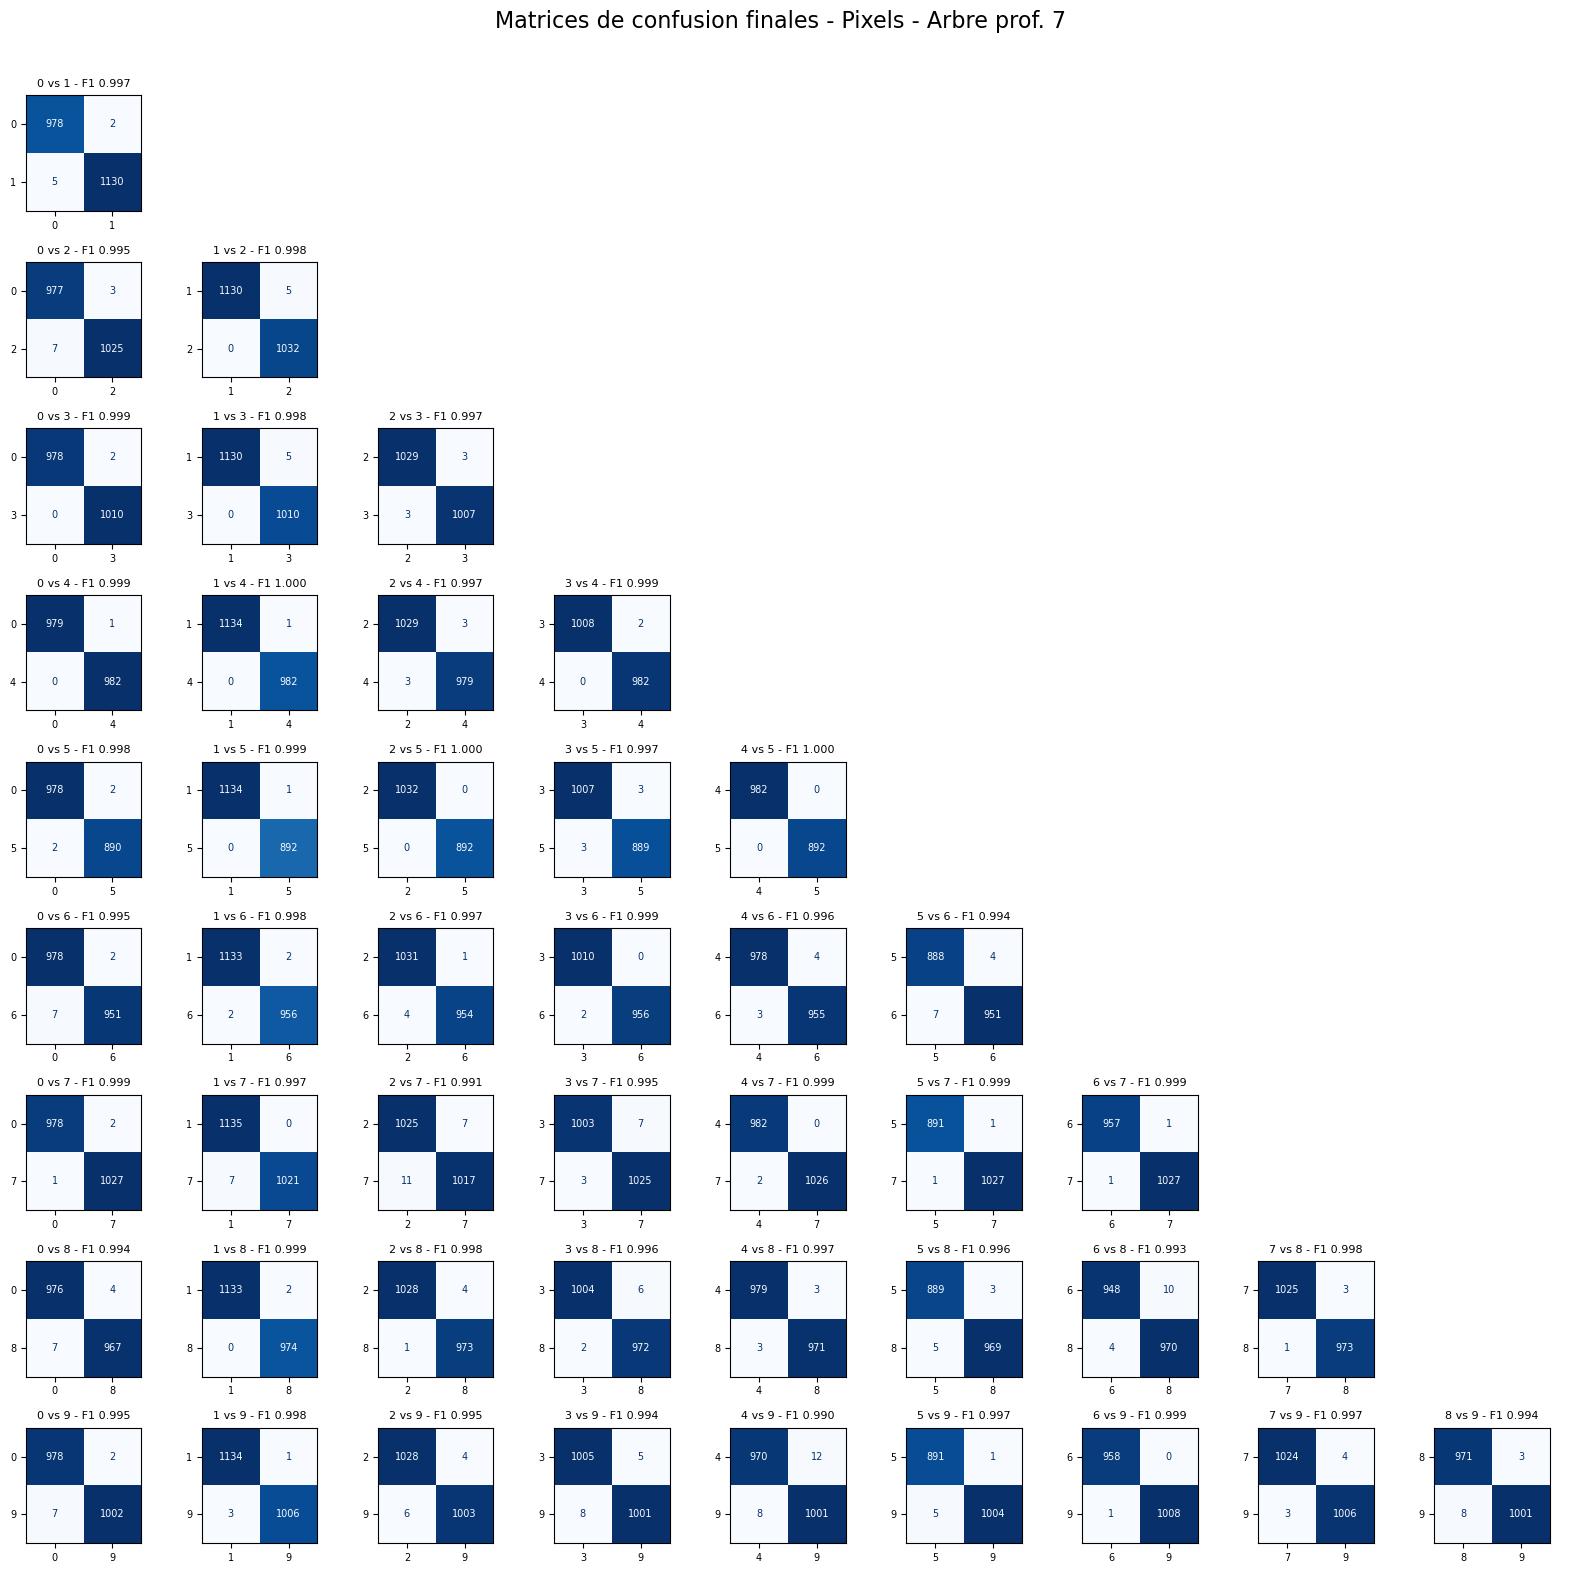

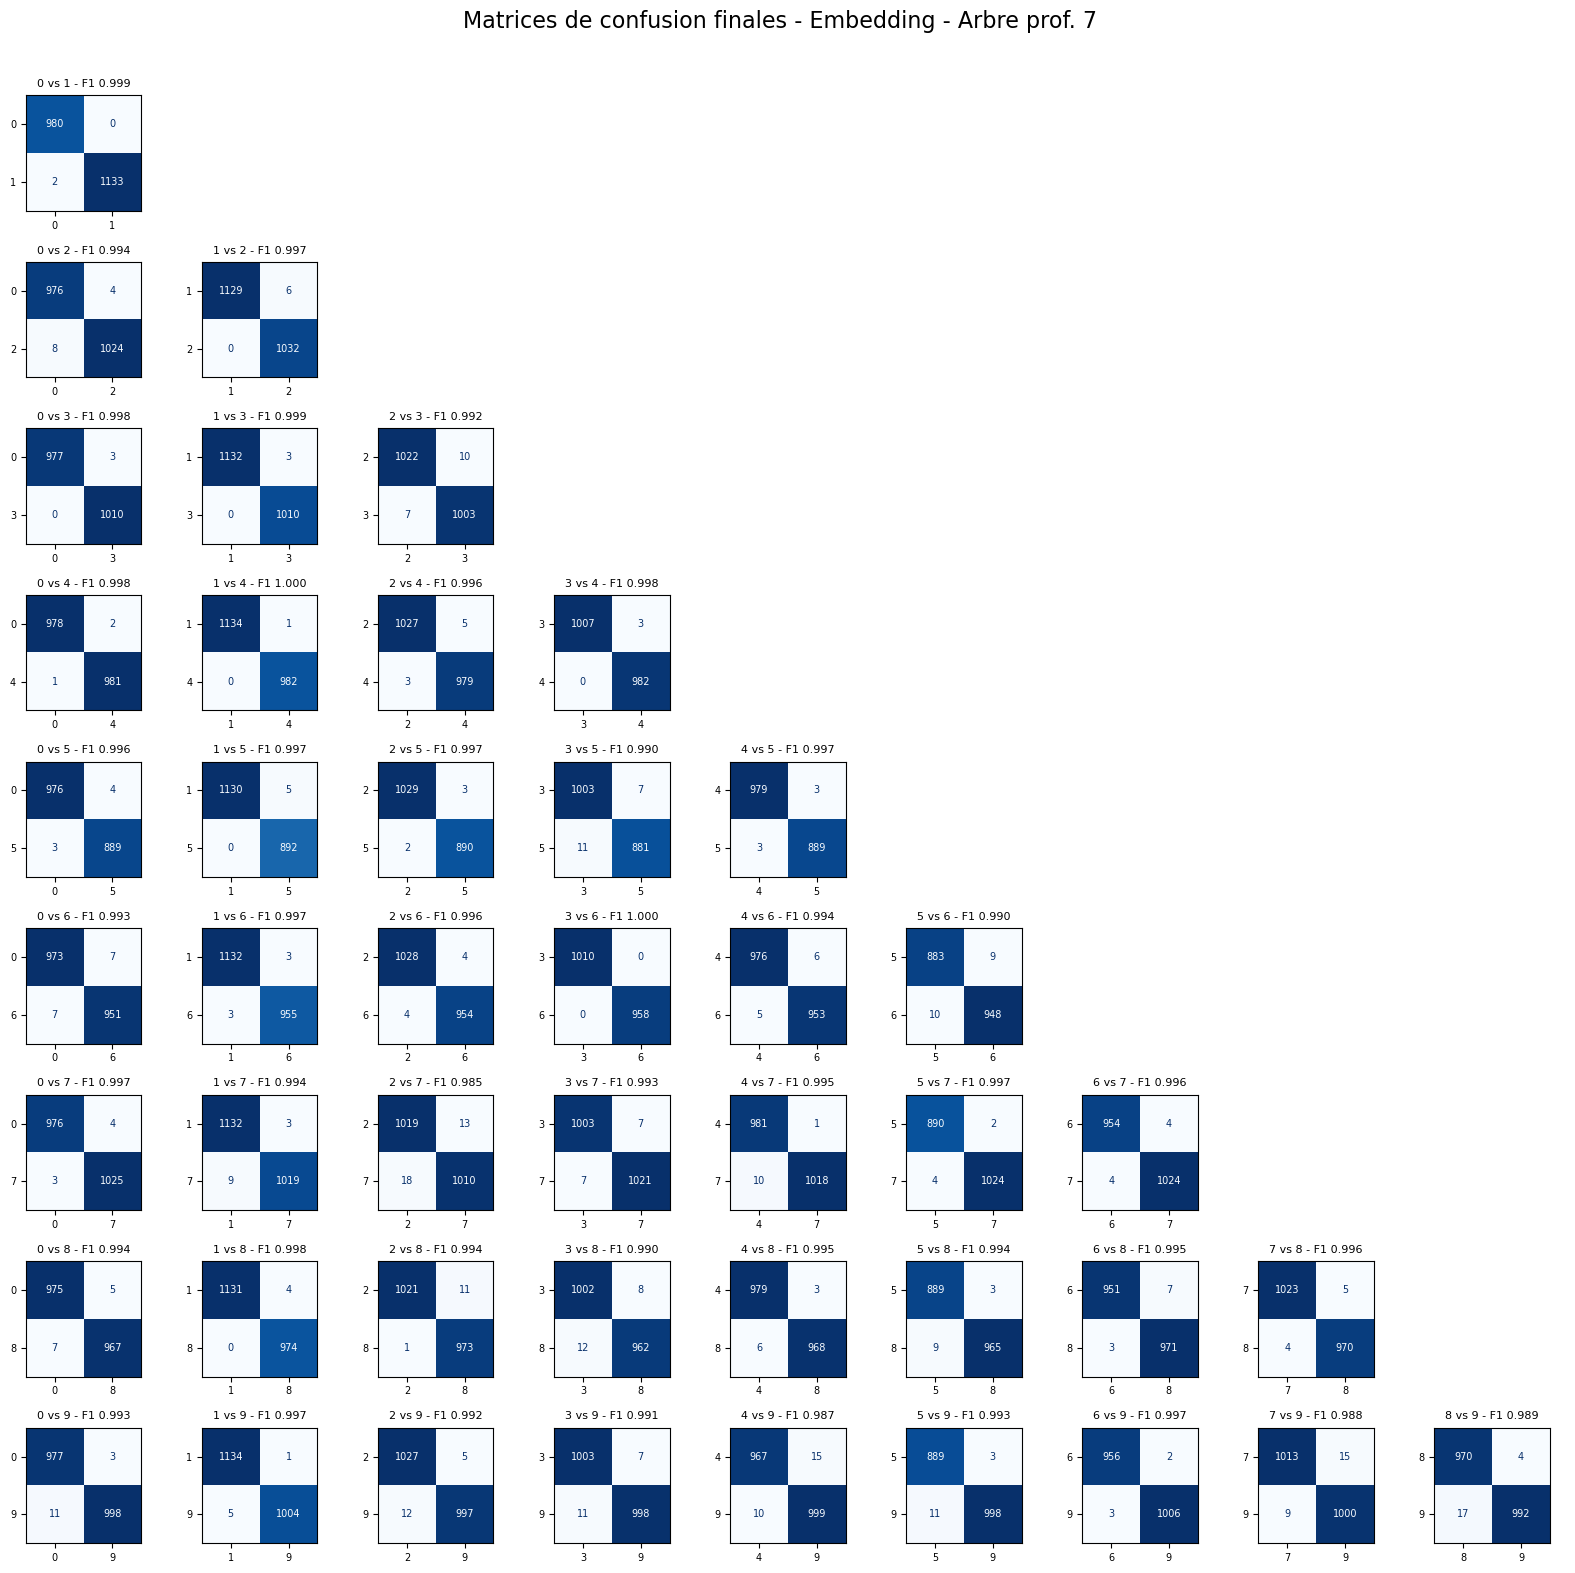

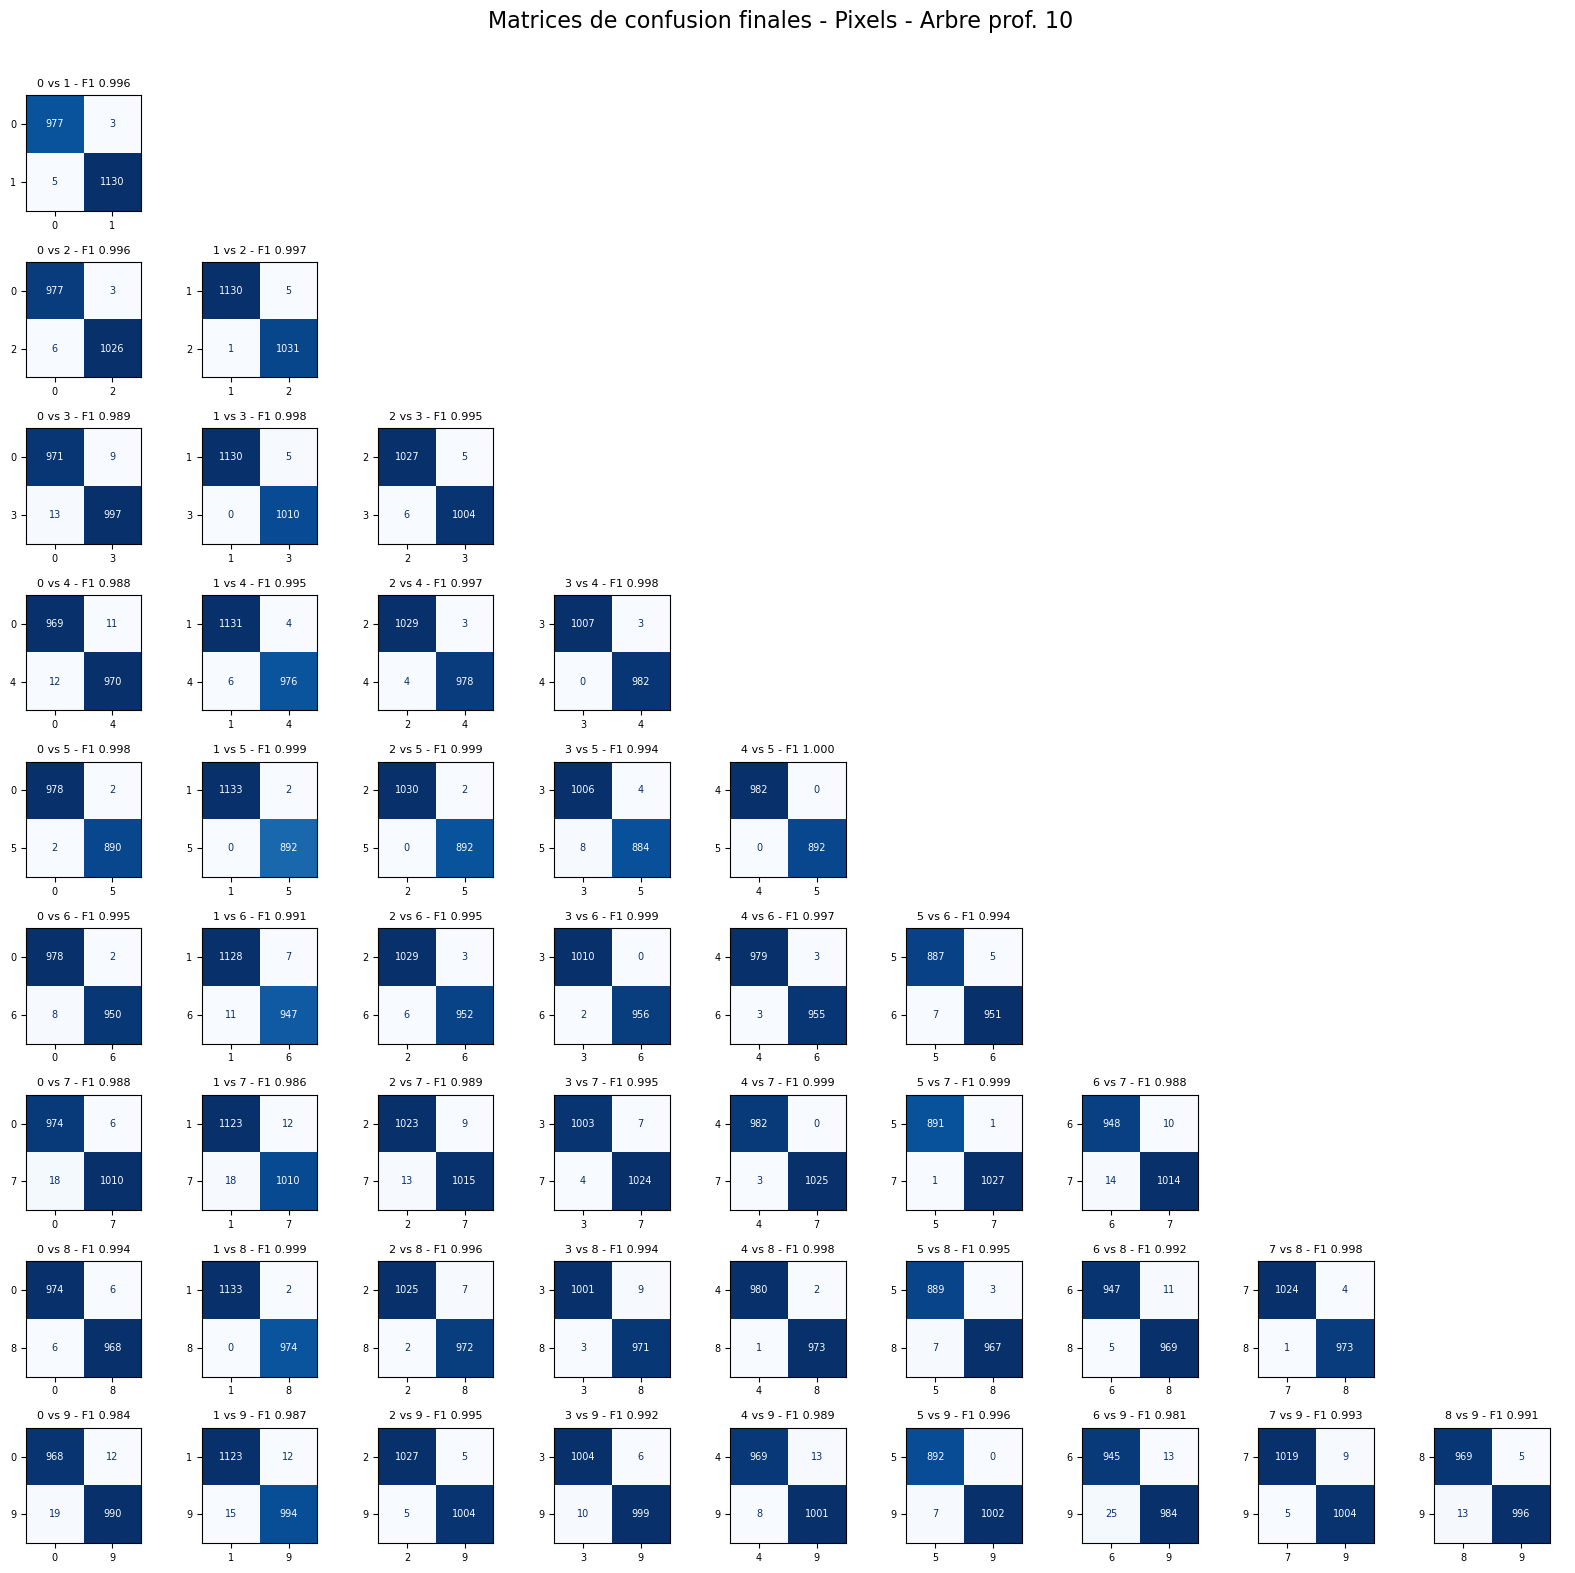

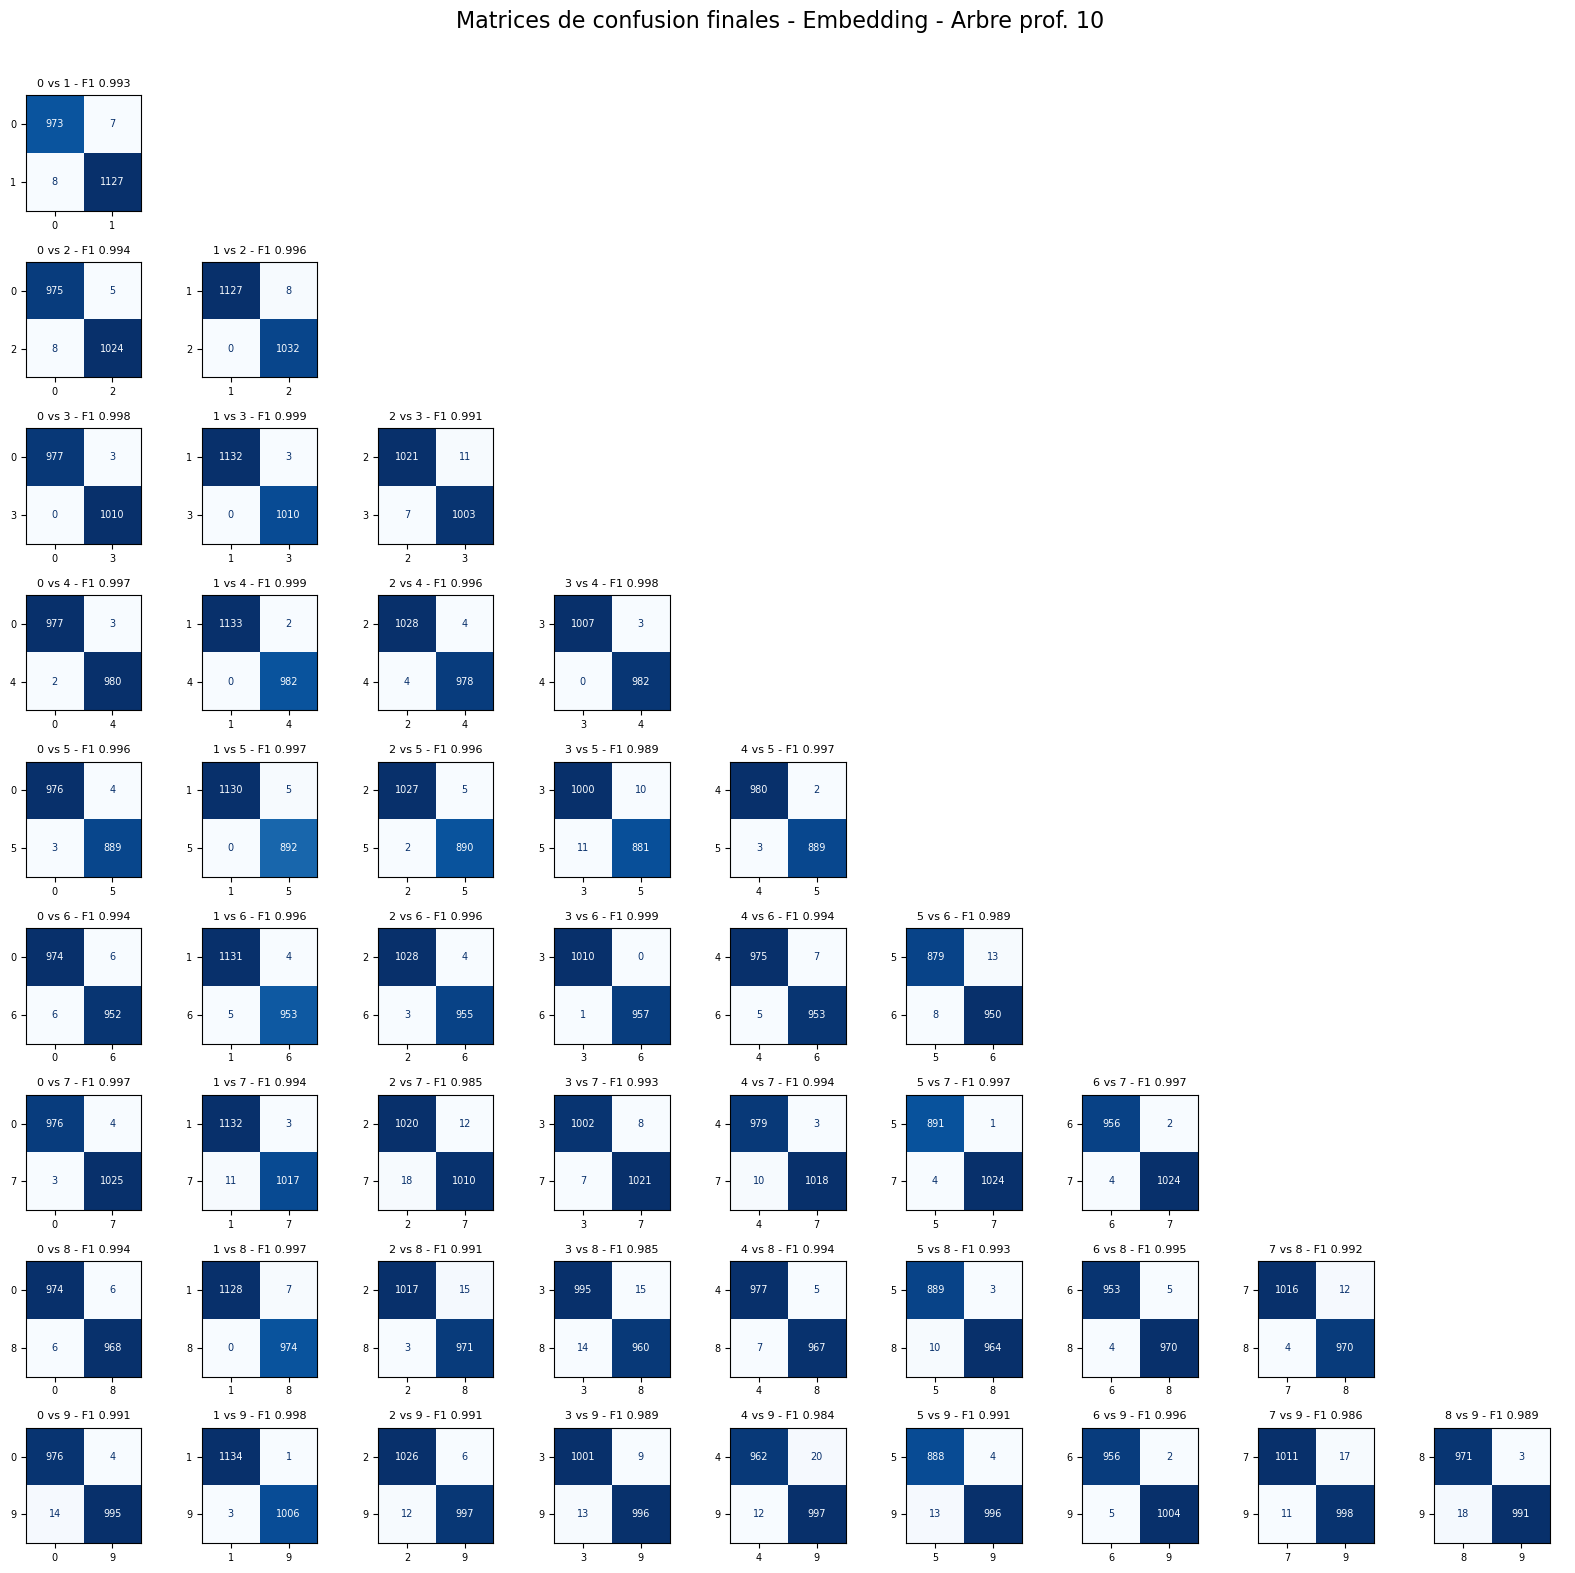

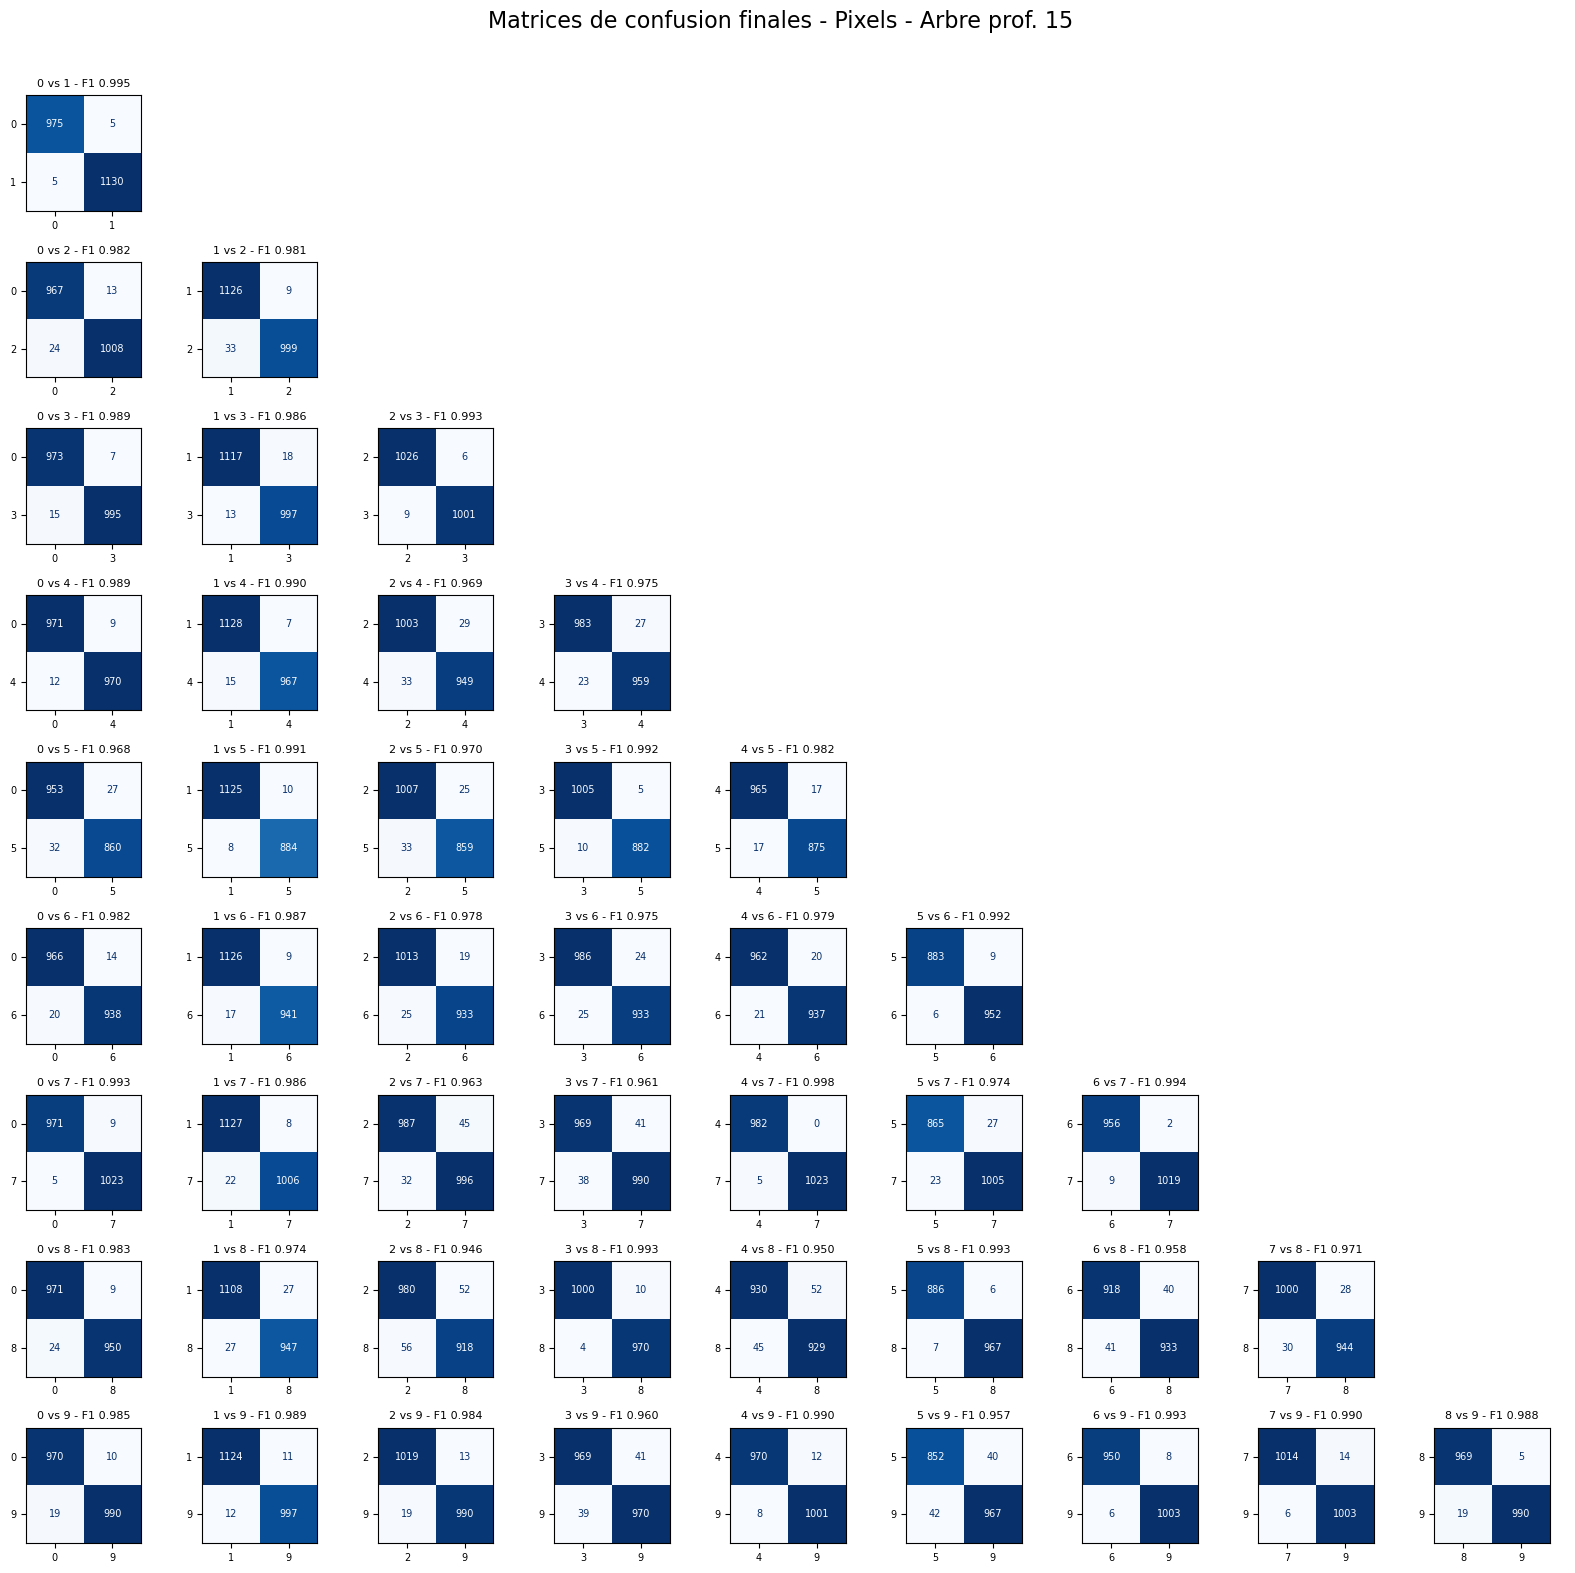

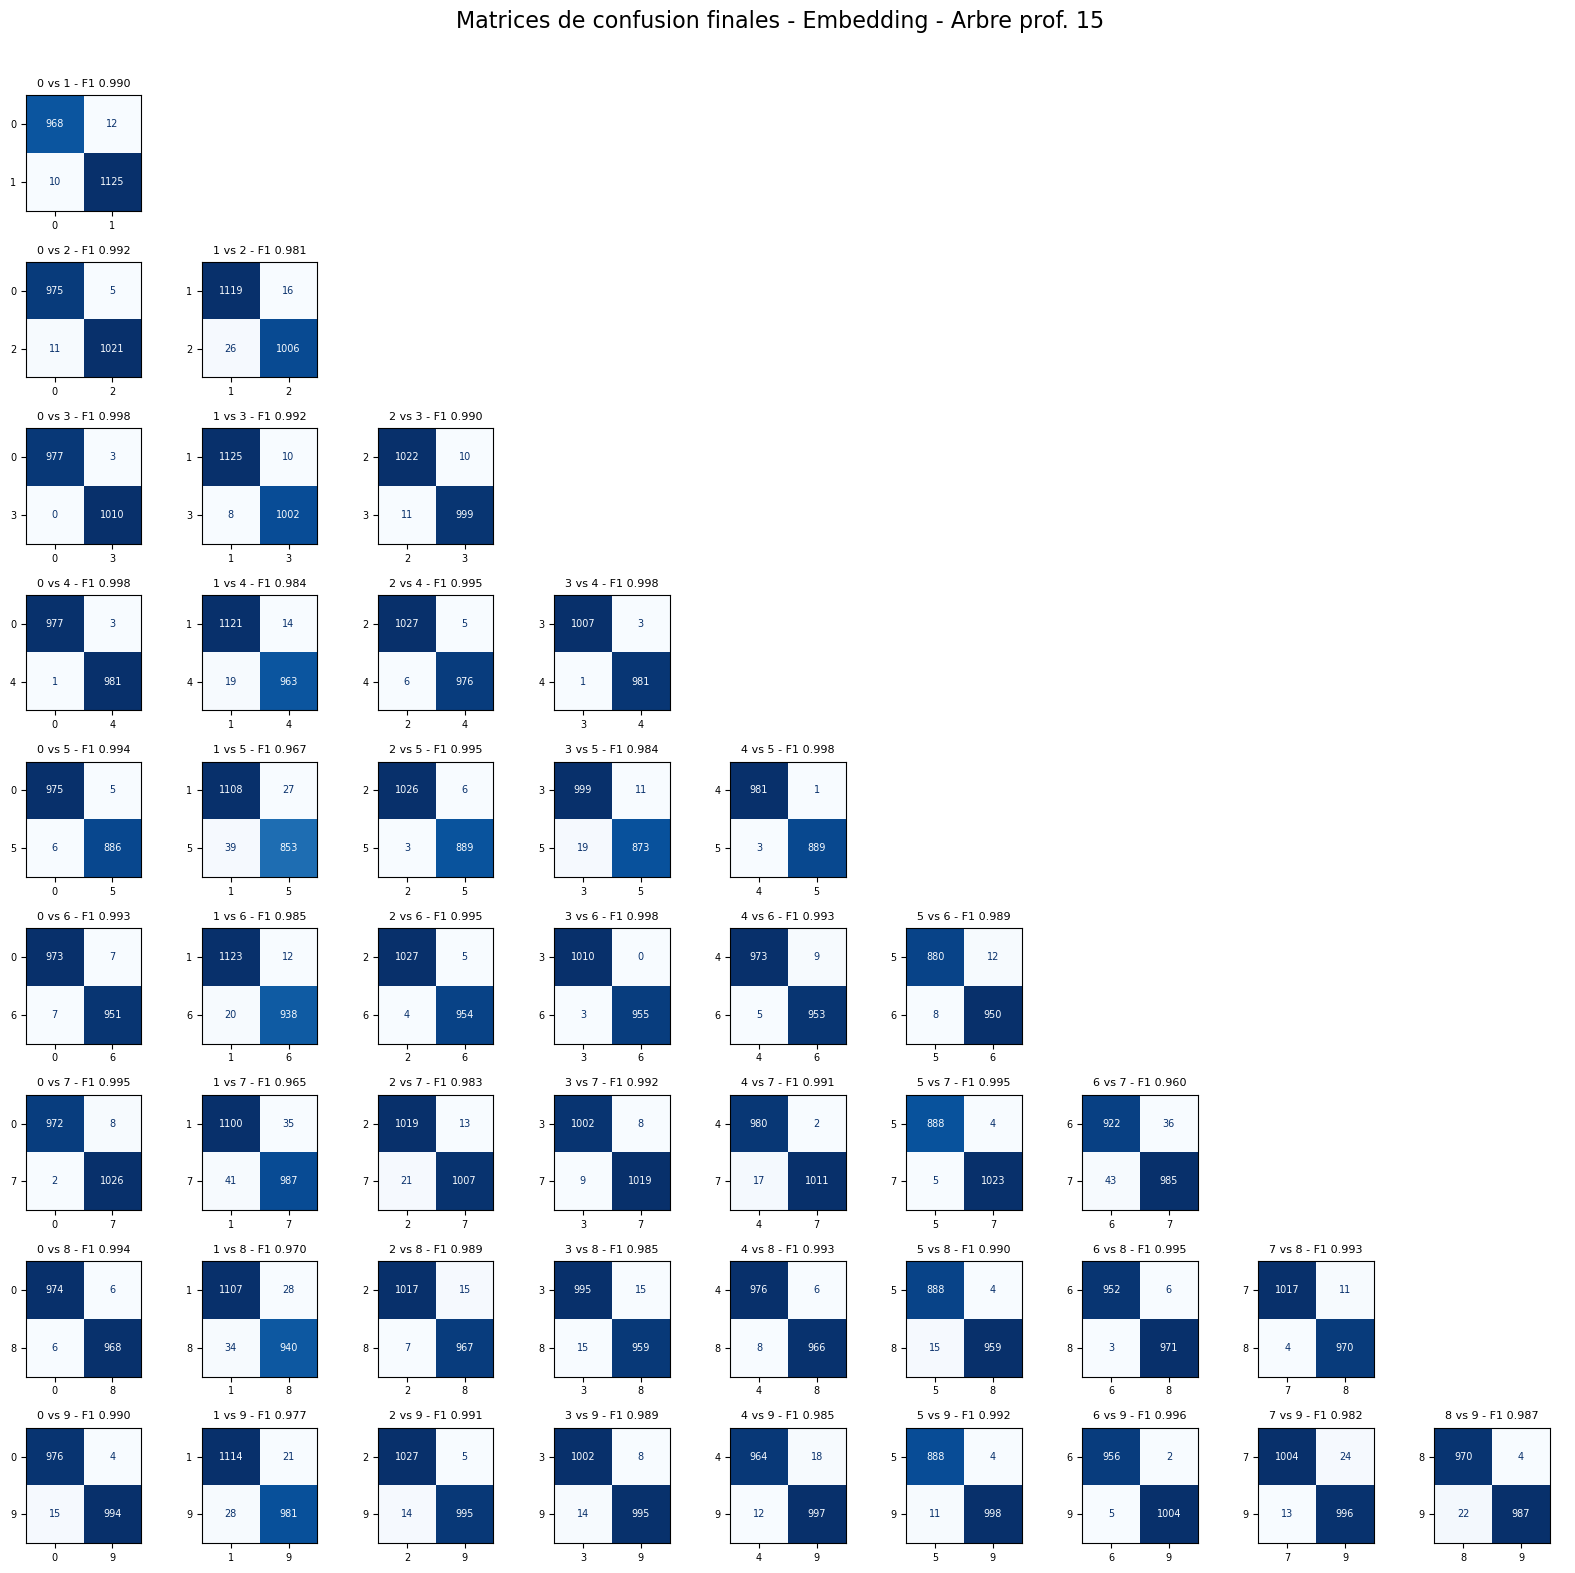

In [35]:
def escalier_confusions(espace, nom):
    """Matrices de confusion finales de toutes les paires, disposées comme le tableau des paires :
    colonne = premier chiffre, ligne = second chiffre."""
    fig, axs = plt.subplots(9, 9, figsize=(16, 16))
    for ax in axs.flat:
        ax.axis("off")

    for a, b in PAIRES:
        m = resultats_globaux[f"{a}_{b}"]["modeles"][espace][nom]
        cm = m["confusions"][max(m["confusions"])]      # matrice à la dernière étape de boosting
        ax = axs[b - 1, a]
        ax.axis("on")
        ConfusionMatrixDisplay(cm, display_labels=[str(a), str(b)]).plot(
            ax=ax, cmap="Blues", colorbar=False, text_kw={"fontsize": 7})
        ax.set_title(f"{a} vs {b} - F1 {m['f1_test'][-1]:.3f}", fontsize=8)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(labelsize=7)

    fig.suptitle(f"Matrices de confusion finales - {espace} - {nom}", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    nom_fichier = f"escalier_{espace}_{nom}".replace(" ", "_").replace(".", "")
    fig.savefig(os.path.join("figures", nom_fichier + ".png"), dpi=110)
    plt.show()


for nom in NOMS_MODELES:
    for espace in ESPACES:
        escalier_confusions(espace, nom)


In [37]:
# F1 final (test) pour chaque paire, chaque espace et chaque classifieur faible
tableau = pd.DataFrame(
    {(espace, nom): {paire: res["modeles"][espace][nom]["f1_test"][-1] for paire, res in resultats_globaux.items()}
     for espace in ESPACES for nom in NOMS_MODELES})
tableau.index.name = "Paire"
tableau.loc["Moyenne"] = tableau.mean()

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 50)
# en vert : le meilleur modèle de chaque paire
display(tableau.style.format("{:.4f}").highlight_max(axis=1, color="lightgreen"))

# Sauvegarde des résultats dans le dossier figures, pour le rapport et pour Excel
os.makedirs("figures", exist_ok=True)
tableau.round(4).to_csv(os.path.join("figures", "tableau_f1_toutes_paires.csv"))                    # pour Excel / le rapport
tableau.style.format("{:.4f}").highlight_max(axis=1, color="lightgreen").to_html(
    os.path.join("figures", "tableau_f1_toutes_paires.html"))                                       # version colorée



**Classifieur faible.** Les arbres de profondeur 5 et 7 sont les meilleurs dans les deux espaces de descriptions. Au dela d'une profondeur de 7 pour les arbres, les résultats se dégradent, on peut émettre l'hypothèse qu'a partir d'une profondeur de 7, le classifieur n'est plus assez faible.


**Pixels ou embedding ?** L'embedding à 64 neurones fait presque aussi bien que les 784 pixels : environ 0,3 point de F1 de moins pour les stumps et les arbres de profondeur 5, et un résultat identique pour le perceptron.

L'embedding reste donc une représentation compacte intéressante, mais le MLP, entraîné à reconstruire les images et non à les classer, perd une partie des détails fins qui séparent les chiffres proches.

**Lien avec les sections précédentes.** Les trois paires étudiées en détail illustrent bien ces niveaux de difficulté : 3 vs 8 fait partie des paires les plus difficiles, 2 vs 9 est intermédiaire, et 1 vs 7 est facile malgré la ressemblance apparente des deux chiffres. Les F1 obtenus avec AdaBoostClassifier (sections 2 et 3) sont cohérents avec ceux de l'étude complète, par exemple 0,9965 pour 3 vs 8 avec les arbres de profondeur 5 dans les deux cas.

Le notebook etude_complete_toute_paires.ipynb permet de visualiser l'ensemble de ces résultats.